# Building Damage Assessment — ResNet50 Siamese U-Net + Streamlit

This notebook continues the xBD building-damage project using a **smaller pilot subset** to reduce storage and training time. It keeps the dataset in Colab's temporary disk and saves only checkpoints and app files in Google Drive.

**Pipeline:** download selected shards → inspect and validate data → compress/extract a small subset → train/validate ResNet50 Siamese U-Net → test on a separate shard → export a Streamlit application.

**Important limitations:** the pilot subset is not the full xBD benchmark. Its metrics should be described as subset results, not full-dataset performance. The xBD mirror is licensed CC BY-NC-SA 4.0; follow its attribution and non-commercial/share-alike terms when using or sharing this project.

**How to use:** choose a Colab GPU runtime, then run cells in order. Every code cell is preceded by a markdown cell explaining its purpose. If the runtime disconnects, reconnect, rerun setup/data/model cells, set `RESUME_TRAINING = True` in the training cell, and continue.

## 0. Runtime setup

**What this cell does:** checks whether Colab has an NVIDIA GPU and installs the libraries used for Parquet reading, image processing, model training, and the Streamlit export. A GPU is strongly recommended for training.

In [ ]:
!nvidia-smi
!pip -q install segmentation-models-pytorch huggingface_hub pyarrow opencv-python-headless streamlit

Tue Nov 24 16:15:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P8             16W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 1. Connect Google Drive and define storage paths

**What this cell does:** mounts your new Google Drive account and creates a dedicated project folder. The dataset will NOT be stored in Drive. Only the best model, resumable checkpoint, training log, and Streamlit source files will be saved there. The folder name is new so this notebook does not overwrite your previous `xbd_ckpt` work.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
from pathlib import Path

PROJECT_DRIVE = '/content/drive/MyDrive/Building_Damage_ResNet50'
CHECKPOINT_DIR = os.path.join(PROJECT_DRIVE, 'checkpoints')
APP_DIR = os.path.join(PROJECT_DRIVE, 'streamlit_app')
for folder in [PROJECT_DRIVE, CHECKPOINT_DIR, APP_DIR]:
    os.makedirs(folder, exist_ok=True)

BEST_CKPT = os.path.join(CHECKPOINT_DIR, 'resnet50_damage_best.pt')
LATEST_CKPT = os.path.join(CHECKPOINT_DIR, 'resnet50_damage_latest.pt')
LOG_CSV = os.path.join(PROJECT_DRIVE, 'training_log.csv')

print('Drive project folder:', PROJECT_DRIVE)
print('Best checkpoint:', BEST_CKPT)
print('Latest checkpoint:', LATEST_CKPT)
print('Existing project files:', os.listdir(PROJECT_DRIVE))

Mounted at /content/drive
Drive project folder: /content/drive/MyDrive/Building_Damage_ResNet50
Best checkpoint: /content/drive/MyDrive/Building_Damage_ResNet50/checkpoints/resnet50_damage_best.pt
Latest checkpoint: /content/drive/MyDrive/Building_Damage_ResNet50/checkpoints/resnet50_damage_latest.pt
Existing project files: ['checkpoints', 'streamlit_app']


## 2. Imports, reproducibility, and device selection

**What this cell does:** imports the libraries used throughout the notebook, fixes random seeds for more repeatable experiments, selects GPU when available, and defines the image normalization values used by ImageNet-pretrained ResNet50. These normalization values must also be used by the Streamlit app.

In [ ]:
import io, glob, gc, random, shutil, hashlib, json, csv, math, time
import numpy as np
import cv2
import pyarrow.parquet as pq
import torch
import torch.nn as nn
import torch.nn.functional as F
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from huggingface_hub import hf_hub_download, HfApi
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('WARNING: CPU selected. Training will be much slower.')

MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)
CLASS_NAMES = ['background', 'no damage', 'minor damage', 'major damage', 'destroyed']
CLASS_COLORS = np.array([[0,0,0], [0,200,0], [255,255,0], [255,140,0], [255,0,0]], dtype=np.uint8)
NUM_CLASSES = 5

Device: cuda
GPU: Tesla T4


## 3. Choose a small, reproducible xBD subset

**What this cell does:** sets the exact shard IDs and sample limits. The starting configuration uses two training shards, one validation shard, and later one test shard. It caps extraction at 300 training samples and 120 validation samples. Increase these limits only after the small run works and you have checked Colab disk space.

The selected training/validation shards are downloaded to `/content`, not Google Drive. A shard is roughly 500 MB, so the initial train+validation download is around 1.5 GB. The test shard is downloaded later, only when you reach the testing section.

In [ ]:
REPO_ID = 'kshitijrajsharma/xview2-xbd'
REPO_TYPE = 'dataset'
PARQUET_DIR = '/content/xbd_parquet_subset'
DATA_DIR = '/content/xbd_small'
TRAIN_ROOT = os.path.join(DATA_DIR, 'train')
VAL_ROOT = os.path.join(DATA_DIR, 'val')
TEST_ROOT = os.path.join(DATA_DIR, 'test')
os.makedirs(PARQUET_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

TRAIN_SHARD_IDS = [0, 1]   # two of the 17 training shards
VAL_SHARD_IDS = [0]        # one of the 6 holdout shards
TEST_SHARD_IDS = [0]       # one of the 6 test shards, downloaded later
MAX_TRAIN_SAMPLES = 300
MAX_VAL_SAMPLES = 120
MAX_TEST_SAMPLES = 120

print('Train shard IDs:', TRAIN_SHARD_IDS)
print('Validation shard IDs:', VAL_SHARD_IDS)
print('Training/validation sample caps:', MAX_TRAIN_SAMPLES, MAX_VAL_SAMPLES)
print('Colab disk before download:')
!df -h /content | tail -1

Train shard IDs: [0, 1]
Validation shard IDs: [0]
Training/validation sample caps: 300 120
Colab disk before download:
overlay         113G  237M  113G   1% /


## 4. Inspect the Hugging Face dataset repository

**What this cell does:** confirms that the expected Parquet files exist and prints the selected shard names. It does not download the full 24 GB dataset.

In [ ]:
repo_files = HfApi().list_repo_files(REPO_ID, repo_type=REPO_TYPE)
parquet_names = [p for p in repo_files if p.endswith('.parquet')]
print('Parquet shards in repository:', len(parquet_names))
for split, ids, total in [('train', TRAIN_SHARD_IDS, 17), ('hold', VAL_SHARD_IDS, 6), ('test', TEST_SHARD_IDS, 6)]:
    for shard_id in ids:
        filename = f'data/{split}-{shard_id:05d}-of-{total:05d}.parquet'
        if filename not in parquet_names:
            raise FileNotFoundError(f'Expected shard not found: {filename}')
        print('Found:', filename)

Parquet shards in repository: 50
Found: data/train-00000-of-00017.parquet
Found: data/train-00001-of-00017.parquet
Found: data/hold-00000-of-00006.parquet
Found: data/test-00000-of-00006.parquet


## 5. Download only the selected training and validation shards

**What this cell does:** downloads the two selected training Parquet files and one holdout file into Colab temporary storage. It skips files that are already present, which makes rerunning this cell safer. The test split is intentionally not downloaded yet.

In [ ]:
def download_shards(split, shard_ids, total_shards):
    downloaded = []
    for shard_id in shard_ids:
        filename = f'data/{split}-{shard_id:05d}-of-{total_shards:05d}.parquet'
        local_path = os.path.join(PARQUET_DIR, filename)
        if not os.path.exists(local_path):
            print('Downloading', filename)
            hf_hub_download(
                repo_id=REPO_ID,
                repo_type=REPO_TYPE,
                filename=filename,
                local_dir=PARQUET_DIR
            )
        else:
            print('Already downloaded:', local_path)
        if not os.path.exists(local_path):
            # hf_hub_download may return a path in the local cache depending on hub version.
            local_path = hf_hub_download(repo_id=REPO_ID, repo_type=REPO_TYPE,
                                         filename=filename, local_dir=PARQUET_DIR)
        downloaded.append(local_path)
    return downloaded

TRAIN_PARQUETS = download_shards('train', TRAIN_SHARD_IDS, 17)
VAL_PARQUETS = download_shards('hold', VAL_SHARD_IDS, 6)
print('Train files:', TRAIN_PARQUETS)
print('Validation files:', VAL_PARQUETS)
!du -sh /content/xbd_parquet_subset
!df -h /content | tail -1

data/train-00000-of-00017.parquet: reconstructing file:   0%|          |  0.00B /  509MB            

data/train-00000-of-00017.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00017.parquet: reconstructing file:   0%|          |  0.00B /  508MB            

data/train-00001-of-00017.parquet: downloading bytes:           |  0.00B            

data/hold-00000-of-00006.parquet: reconstructing file:   0%|          |  0.00B /  477MB            

data/hold-00000-of-00006.parquet: downloading bytes:           |  0.00B            

Train files: ['/content/xbd_parquet_subset/data/train-00000-of-00017.parquet', '/content/xbd_parquet_subset/data/train-00001-of-00017.parquet']
Validation files: ['/content/xbd_parquet_subset/data/hold-00000-of-00006.parquet']
1.4G	/content/xbd_parquet_subset
overlay         113G  1.7G  111G   2% /


## 6. Inspect the actual schema, images, and damage masks

**What this cell does:** opens one row from a selected training shard and checks the data structure. The original notebook's sample inspection showed 1024×1024 RGB satellite images and grayscale masks with class IDs 0–4. This cell repeats that inspection for the newly downloaded subset instead of blindly assuming every mask is correct.

In [ ]:
first_pf = pq.ParquetFile(TRAIN_PARQUETS[0])
print(first_pf.schema_arrow)
row = next(first_pf.iter_batches(batch_size=1)).to_pylist()[0]
for key, value in row.items():
    print(key, type(value).__name__, repr(value)[:120])

pre_sample = np.array(Image.open(io.BytesIO(row['t1_image']['bytes'])).convert('RGB'))
post_sample = np.array(Image.open(io.BytesIO(row['t2_image']['bytes'])).convert('RGB'))
mask_sample_img = Image.open(io.BytesIO(row['t2_mask']['bytes']))
mask_sample = np.array(mask_sample_img)
print('Pre image:', pre_sample.shape, pre_sample.dtype)
print('Post image:', post_sample.shape, post_sample.dtype)
print('Post mask:', mask_sample.shape, mask_sample.dtype, 'mode:', mask_sample_img.mode)
print('Mask values:', np.unique(mask_sample)[:30])
if pre_sample.shape != post_sample.shape:
    raise ValueError('Pre/post sample dimensions do not match.')
if mask_sample.ndim != 2:
    raise ValueError('Expected a single-channel grayscale damage mask; inspect source encoding before training.')

t1_image: struct<bytes: binary, path: string>
  child 0, bytes: binary
  child 1, path: string
t2_image: struct<bytes: binary, path: string>
  child 0, bytes: binary
  child 1, path: string
t1_mask: struct<bytes: binary, path: string>
  child 0, bytes: binary
  child 1, path: string
t2_mask: struct<bytes: binary, path: string>
  child 0, bytes: binary
  child 1, path: string
image_name: string
-- schema metadata --
huggingface: '{"info": {"features": {"t1_image": {"_type": "Image"}, "t2_' + 144
t1_image dict {'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x04\x00\x00\x00\x04\x00\x08\x02\x00\x00\x00\xf0\x7f\xbc\xd4\x00\
t2_image dict {'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x04\x00\x00\x00\x04\x00\x08\x02\x00\x00\x00\xf0\x7f\xbc\xd4\x00\
t1_mask dict {'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x04\x00\x00\x00\x04\x00\x08\x00\x00\x00\x00Zvt_\x00\x00\x06XIDAT
t2_mask dict {'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x04\x00\x00\x00\x04\x00\x08

## 7. Extract a compressed, capped subset

**What this cell does:** extracts only the first configured number of samples from the selected shards. Satellite images are converted to JPEG (quality 90) to save Colab disk space; damage masks are saved losslessly as PNG so class labels are not altered. It checks dimensions and records invalid rows. Existing complete image/mask pairs are skipped rather than overwritten, so rerunning the cell does not erase extracted work.

The dataset remains in `/content/xbd_small`; it is not copied to Google Drive. If Colab disconnects, temporary data may disappear and can be recreated by rerunning the download and extraction cells.

In [ ]:
from collections import Counter

def extract_compressed(parquet_paths, out_root, max_samples, split_name):
    image_dir = os.path.join(out_root, 'images')
    mask_dir = os.path.join(out_root, 'masks')
    os.makedirs(image_dir, exist_ok=True)
    os.makedirs(mask_dir, exist_ok=True)
    saved = set(os.path.basename(p)[:-4] for p in glob.glob(os.path.join(mask_dir, '*.png')))
    bad_rows = []
    written = 0

    for parquet_path in parquet_paths:
        if len(saved) >= max_samples:
            break
        pf = pq.ParquetFile(parquet_path)
        for batch in pf.iter_batches(batch_size=8):
            for record in batch.to_pylist():
                if len(saved) >= max_samples:
                    break
                sample_name = os.path.basename(record['image_name'])
                if sample_name in saved:
                    continue
                try:
                    pre = Image.open(io.BytesIO(record['t1_image']['bytes'])).convert('RGB')
                    post = Image.open(io.BytesIO(record['t2_image']['bytes'])).convert('RGB')
                    mask_img = Image.open(io.BytesIO(record['t2_mask']['bytes']))
                    mask = np.array(mask_img)
                    if mask.ndim != 2:
                        raise ValueError(f'Mask is not grayscale: shape={mask.shape}')
                    if pre.size != post.size or pre.size != (mask.shape[1], mask.shape[0]):
                        raise ValueError(f'Dimension mismatch: pre={pre.size}, post={post.size}, mask={mask.shape}')
                    if pre.size != (1024, 1024):
                        raise ValueError(f'Unexpected image dimensions: {pre.size}')

                    pre.save(os.path.join(image_dir, sample_name + '_pre_disaster.jpg'),
                             format='JPEG', quality=90, optimize=True)
                    post.save(os.path.join(image_dir, sample_name + '_post_disaster.jpg'),
                              format='JPEG', quality=90, optimize=True)
                    Image.fromarray(mask.astype(np.uint8), mode='L').save(
                        os.path.join(mask_dir, sample_name + '.png'), format='PNG', optimize=True)
                    saved.add(sample_name)
                    written += 1
                except Exception as exc:
                    bad_rows.append((record.get('image_name', 'unknown'), str(exc)))
            if len(saved) >= max_samples:
                break

    print(f'{split_name}: {len(saved)} complete samples; newly written {written}; rejected rows {len(bad_rows)}')
    if bad_rows[:5]:
        print('First rejected rows:', bad_rows[:5])
    if not saved:
        raise RuntimeError(f'No usable {split_name} samples were extracted.')
    return bad_rows

train_bad_rows = extract_compressed(TRAIN_PARQUETS, TRAIN_ROOT, MAX_TRAIN_SAMPLES, 'train')
val_bad_rows = extract_compressed(VAL_PARQUETS, VAL_ROOT, MAX_VAL_SAMPLES, 'validation')
print('Compressed extracted data size:')
!du -sh /content/xbd_small
!df -h /content | tail -1

/tmp/ipykernel_431/433869292.py:39: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(mask.astype(np.uint8), mode='L').save(


train: 300 complete samples; newly written 300; rejected rows 0
validation: 120 complete samples; newly written 120; rejected rows 0
Compressed extracted data size:
210M	/content/xbd_small
overlay         113G  1.9G  111G   2% /


## 8. Data quality audit and class distribution

**What this cell does:** verifies that every saved mask has both matching images, all three files can be opened, dimensions match, and mask labels are counted. Valid labels are 0–4. Any unexpected values are reported and converted to `255` (ignore in loss/metrics) when the Dataset loads them; they are never silently converted to background.

In [ ]:
def audit_split(root, split_name):
    mask_paths = sorted(glob.glob(os.path.join(root, 'masks', '*.png')))
    counts = np.zeros(256, dtype=np.int64)
    issues = []
    for mask_path in mask_paths:
        name = os.path.basename(mask_path)[:-4]
        pre_path = os.path.join(root, 'images', name + '_pre_disaster.jpg')
        post_path = os.path.join(root, 'images', name + '_post_disaster.jpg')
        try:
            if not (os.path.exists(pre_path) and os.path.exists(post_path)):
                raise FileNotFoundError('Missing paired pre/post image')
            pre = np.array(Image.open(pre_path).convert('RGB'))
            post = np.array(Image.open(post_path).convert('RGB'))
            mask = np.array(Image.open(mask_path))
            if pre.shape[:2] != post.shape[:2] or pre.shape[:2] != mask.shape:
                raise ValueError(f'Shape mismatch: {pre.shape}, {post.shape}, {mask.shape}')
            if mask.ndim != 2:
                raise ValueError('Mask is not single-channel')
            counts += np.bincount(mask.ravel(), minlength=256)
        except Exception as exc:
            issues.append((name, str(exc)))
    print(f'--- {split_name} audit ---')
    print('Samples:', len(mask_paths), '| issues:', len(issues))
    print('Label pixel counts:', {int(i): int(v) for i, v in enumerate(counts) if v})
    print('Unexpected label values:', [int(i) for i, v in enumerate(counts) if v and i not in range(5)])
    if issues:
        print('First issues:', issues[:5])
    if not mask_paths or issues:
        raise RuntimeError(f'{split_name} data audit failed; fix the reported issues before training.')
    return counts

train_label_counts = audit_split(TRAIN_ROOT, 'train')
val_label_counts = audit_split(VAL_ROOT, 'validation')

--- train audit ---
Samples: 300 | issues: 0
Label pixel counts: {0: 294673584, 1: 15007121, 2: 1440516, 3: 2262123, 4: 1189456}
Unexpected label values: []
--- validation audit ---
Samples: 120 | issues: 0
Label pixel counts: {0: 118489623, 1: 6019444, 2: 550980, 3: 553387, 4: 215686}
Unexpected label values: []


## 8A. Free temporary space after successful extraction and audit

**What this cell does:** removes only the downloaded Parquet shard files from Colab temporary storage after the compressed image/mask files have passed the audit. It does not touch Google Drive checkpoints or the extracted dataset. If the runtime disconnects later, the temporary dataset will still need to be downloaded and extracted again.

In [ ]:
import os
import shutil

DRIVE_DATA_DIR = os.path.join(
    PROJECT_DRIVE, 'dataset', 'xbd_small'
)

os.makedirs(os.path.dirname(DRIVE_DATA_DIR), exist_ok=True)

# Copy extracted dataset to Google Drive
shutil.copytree(
    DATA_DIR,
    DRIVE_DATA_DIR,
    dirs_exist_ok=True
)

# Verify backup
for split in ['train', 'val']:
    images = len(os.listdir(os.path.join(DRIVE_DATA_DIR, split, 'images')))
    masks = len(os.listdir(os.path.join(DRIVE_DATA_DIR, split, 'masks')))

    print(f'{split}: {images} images, {masks} masks')

print('Backup location:', DRIVE_DATA_DIR)

train: 600 images, 300 masks
val: 240 images, 120 masks
Backup location: /content/drive/MyDrive/Building_Damage_ResNet50/dataset/xbd_small


In [ ]:
for parquet_path in TRAIN_PARQUETS + VAL_PARQUETS:
    if os.path.exists(parquet_path):
        os.remove(parquet_path)
print('Removed downloaded train/validation Parquet shards from temporary storage.')
!du -sh /content/xbd_small
!df -h /content | tail -1

Removed downloaded train/validation Parquet shards from temporary storage.
210M	/content/xbd_small
overlay         113G  1.2G  112G   2% /


## 9. Visual quality check

**What this cell does:** displays one paired pre-disaster image, post-disaster image, and ground-truth mask. The mask colours are only for visualization; the stored mask remains the original integer class IDs. Check that the image pair is aligned and the mask is plausible before training.

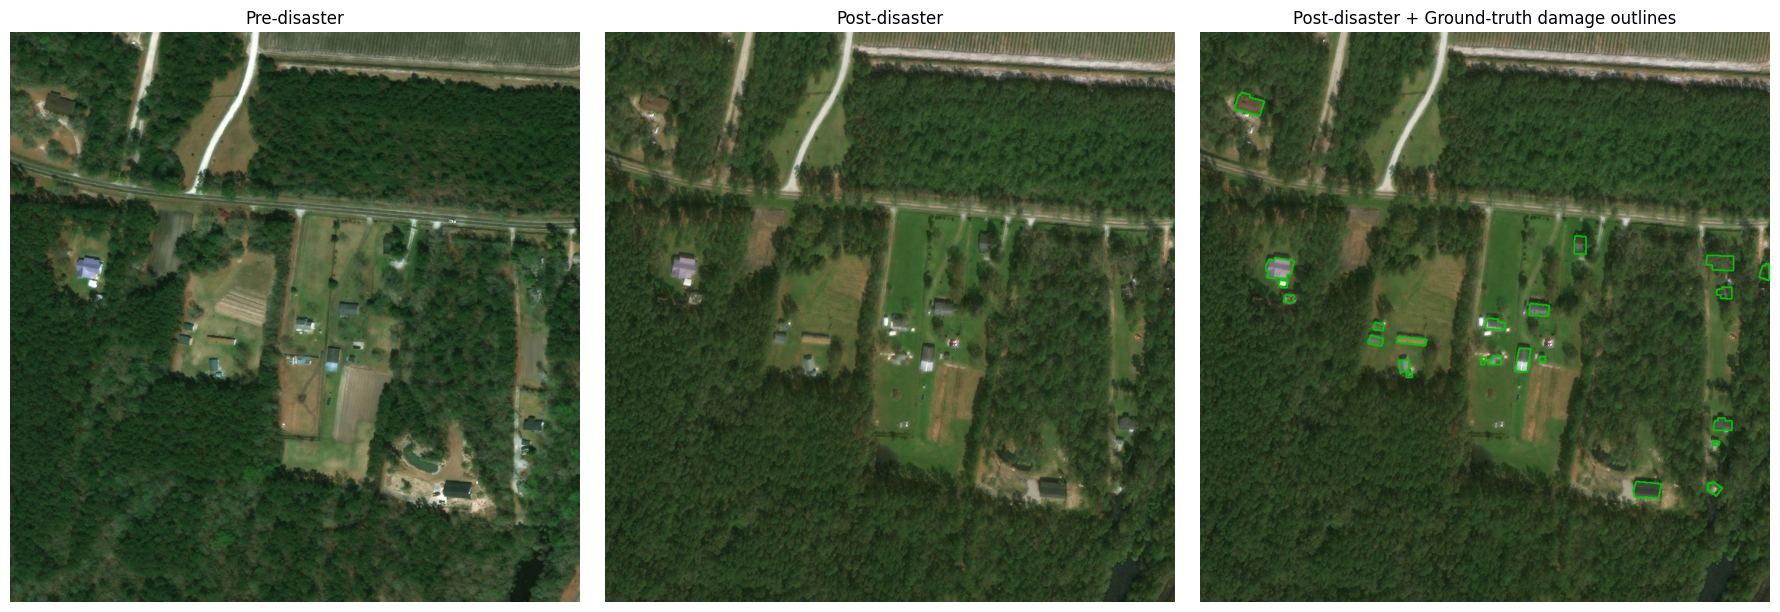

Sample: hurricane-florence_00000212
Mask values: [0 1]


In [ ]:

# Colors for the 4 building damage classes
# Class 0 (background) is intentionally excluded.
DAMAGE_COLORS = {
    1: (0, 200, 0),      # No damage - Green
    2: (255, 220, 0),    # Minor damage - Yellow
    3: (255, 120, 0),    # Major damage - Orange
    4: (230, 0, 0)       # Destroyed - Red
}

def show_sample(root, index=0):
    names = sorted(
        os.path.basename(p)[:-4]
        for p in glob.glob(os.path.join(root, 'masks', '*.png'))
    )

    name = names[index]

    # Load images
    pre = np.array(
        Image.open(os.path.join(root, 'images', name + '_pre_disaster.jpg')).convert('RGB')
    )

    post = np.array(
        Image.open(os.path.join(root, 'images', name + '_post_disaster.jpg')).convert('RGB')
    )

    mask = np.array(
        Image.open(os.path.join(root, 'masks', name + '.png'))
    )

    # Create a copy of the post-disaster image
    vis = post.copy()

    # Draw colored contours for each damage class
    for class_id, color in DAMAGE_COLORS.items():

        class_mask = (mask == class_id).astype(np.uint8)

        contours, _ = cv2.findContours(
            class_mask,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        cv2.drawContours(vis, contours, -1, color, 2)

    # Display results
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(pre)
    axes[0].set_title('Pre-disaster')

    axes[1].imshow(post)
    axes[1].set_title('Post-disaster')

    axes[2].imshow(vis)
    axes[2].set_title('Post-disaster + Ground-truth damage outlines')

    for ax in axes:
        ax.axis('off')

    plt.tight_layout()
    plt.show()

    print('Sample:', name)
    print('Mask values:', np.unique(mask))


show_sample(TRAIN_ROOT, 14)


## 10. Dataset and DataLoaders

**What this cell does:** creates a PyTorch Dataset that loads matching pre/post images and their post-disaster damage masks. Training uses random 512×512 crops plus paired flips/rotations. Validation uses a deterministic centre crop so results are repeatable. ImageNet normalization is applied to both images; masks are not normalized.

In [ ]:
CROP_SIZE = 512
BATCH_SIZE = 2
NUM_WORKERS = 0  # zero workers makes mid-epoch resume more reproducible in Colab

def get_sample_names(root):
    return sorted(os.path.basename(p)[:-4] for p in glob.glob(os.path.join(root, 'masks', '*.png')))

class XBDDataset(Dataset):
    def __init__(self, root, train=False, crop_size=512):
        self.root = root
        self.train = train
        self.crop_size = crop_size
        self.names = get_sample_names(root)
        if not self.names:
            raise RuntimeError(f'No samples found in {root}')

    def __len__(self):
        return len(self.names)

    def __getitem__(self, index):
        name = self.names[index]
        image_dir = os.path.join(self.root, 'images')
        pre = cv2.imread(os.path.join(image_dir, name + '_pre_disaster.jpg'), cv2.IMREAD_COLOR)
        post = cv2.imread(os.path.join(image_dir, name + '_post_disaster.jpg'), cv2.IMREAD_COLOR)
        mask = cv2.imread(os.path.join(self.root, 'masks', name + '.png'), cv2.IMREAD_GRAYSCALE)
        if pre is None or post is None or mask is None:
            raise FileNotFoundError(f'Unreadable sample: {name}')
        pre = cv2.cvtColor(pre, cv2.COLOR_BGR2RGB)
        post = cv2.cvtColor(post, cv2.COLOR_BGR2RGB)
        if pre.shape[:2] != post.shape[:2] or pre.shape[:2] != mask.shape:
            raise ValueError(f'Shape mismatch for {name}')
        mask = np.where(mask <= 4, mask, 255).astype(np.uint8)

        if self.train:
            h, w = mask.shape
            y = random.randint(0, h - self.crop_size)
            x = random.randint(0, w - self.crop_size)
            sl = (slice(y, y + self.crop_size), slice(x, x + self.crop_size))
            pre, post, mask = pre[sl], post[sl], mask[sl]
            if random.random() < 0.5:
                pre, post, mask = pre[:, ::-1], post[:, ::-1], mask[:, ::-1]
            if random.random() < 0.5:
                pre, post, mask = pre[::-1], post[::-1], mask[::-1]
            k = random.randint(0, 3)
            pre, post, mask = np.rot90(pre, k), np.rot90(post, k), np.rot90(mask, k)
        else:
            h, w = mask.shape
            y = max((h - self.crop_size) // 2, 0)
            x = max((w - self.crop_size) // 2, 0)
            sl = (slice(y, y + self.crop_size), slice(x, x + self.crop_size))
            pre, post, mask = pre[sl], post[sl], mask[sl]

        def image_tensor(image):
            image = np.ascontiguousarray(image).astype(np.float32) / 255.0
            image = (image - MEAN) / STD
            return torch.from_numpy(image.transpose(2, 0, 1).astype(np.float32))
        return image_tensor(pre), image_tensor(post), torch.from_numpy(np.ascontiguousarray(mask)).long()

train_ds = XBDDataset(TRAIN_ROOT, train=True, crop_size=CROP_SIZE)
val_ds = XBDDataset(VAL_ROOT, train=False, crop_size=CROP_SIZE)
val_dl = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                    num_workers=NUM_WORKERS, pin_memory=(device.type == 'cuda'))
print('Training samples:', len(train_ds), '| validation samples:', len(val_ds))

Training samples: 300 | validation samples: 120


## 11. Define the ResNet50 Siamese U-Net

**What this cell does:** defines the model. The same ImageNet-pretrained ResNet50 encoder processes both images. At each feature scale, the model combines the pre-disaster features, post-disaster features, and their absolute difference. A U-Net-style decoder then predicts five per-pixel classes.

## 12. Initialize the pretrained ResNet50 model

**What this cell does:** creates the model with ImageNet-pretrained ResNet50 encoder weights, moves it to the selected device, and prints the number of parameters. The pretrained weights are downloaded to the Colab runtime cache, not your Google Drive.

In [ ]:
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    )

class SiamUNet(nn.Module):
    def __init__(self, encoder_name='resnet50', num_classes=5, encoder_weights=None):
        super().__init__()
        self.encoder = smp.encoders.get_encoder(
            encoder_name, in_channels=3, depth=5, weights=encoder_weights
        )
        channels = self.encoder.out_channels
        self.fuse = nn.ModuleList([
            nn.Conv2d(3 * channels[i], channels[i], kernel_size=1)
            for i in range(1, 6)
        ])
        decoder_channels = [256, 128, 64, 32]
        self.decoder = nn.ModuleList()
        previous_channels = channels[5]
        for skip_channels, out_channels in zip(
            [channels[4], channels[3], channels[2], channels[1]], decoder_channels
        ):
            self.decoder.append(conv_block(previous_channels + skip_channels, out_channels))
            previous_channels = out_channels
        self.segmentation_head = nn.Sequential(
            conv_block(previous_channels, 32),
            nn.Conv2d(32, num_classes, kernel_size=1)
        )

    def forward(self, pre, post):
        pre_features = self.encoder(pre)
        post_features = self.encoder(post)
        fused = []
        for i in range(1, 6):
            difference = torch.abs(post_features[i] - pre_features[i])
            combined = torch.cat([pre_features[i], post_features[i], difference], dim=1)
            fused.append(self.fuse[i - 1](combined))
        x = fused[4]
        for j, decoder_block in enumerate(self.decoder):
            x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False)
            x = decoder_block(torch.cat([x, fused[3 - j]], dim=1))
        x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False)
        return self.segmentation_head(x)

model = SiamUNet(encoder_name='resnet50', num_classes=NUM_CLASSES, encoder_weights='imagenet').to(device)
print(f'Model parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} million')

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Model parameters: 49.26 million


## 13. Model shape smoke test

**What this cell does:** sends a dummy pair of 512×512 images through the network and confirms that the output has five channels and the same spatial dimensions as the target mask. This catches architecture/decoder dimension errors before spending time on training.

In [ ]:
model.eval()
with torch.no_grad():
    dummy_pre = torch.zeros(1, 3, CROP_SIZE, CROP_SIZE, device=device)
    dummy_post = torch.zeros(1, 3, CROP_SIZE, CROP_SIZE, device=device)
    dummy_output = model(dummy_pre, dummy_post)
print('Model output shape:', tuple(dummy_output.shape))
assert dummy_output.shape == (1, NUM_CLASSES, CROP_SIZE, CROP_SIZE)
del dummy_pre, dummy_post, dummy_output
torch.cuda.empty_cache() if device.type == 'cuda' else None
print('Smoke test passed.')

Model output shape: (1, 5, 512, 512)
Smoke test passed.


## 14. Loss, optimizer, scheduler, and metrics

**What this cell does:** defines a class-weighted cross-entropy plus Dice loss to help with rare damage categories, AdamW optimization, a cosine learning-rate schedule, mixed-precision scaling on GPU, and pixel-level F1 metrics. Unknown mask pixels (`255`) are ignored.

In [ ]:
class_weights = torch.tensor([0.3, 1.0, 3.0, 3.0, 3.0], device=device)
ce_loss = nn.CrossEntropyLoss(weight=class_weights, ignore_index=255)
dice_loss = smp.losses.DiceLoss(mode='multiclass', ignore_index=255)

def criterion(outputs, targets):
    return ce_loss(outputs, targets) + dice_loss(outputs, targets)

EPOCHS = 8
LEARNING_RATE = 2e-4
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))

def confusion_matrix(pred, target, num_classes=5):
    valid = target != 255
    values = target[valid] * num_classes + pred[valid]
    return torch.bincount(values, minlength=num_classes * num_classes).reshape(num_classes, num_classes).cpu()

def f1_from_confusion(cm):
    tp = cm.diag().float()
    fp = cm.sum(0).float() - tp
    fn = cm.sum(1).float() - tp
    return (2 * tp / (2 * tp + fp + fn).clamp(min=1)).numpy()

print('Epochs:', EPOCHS, '| batch size:', BATCH_SIZE, '| learning rate:', LEARNING_RATE)

Epochs: 8 | batch size: 2 | learning rate: 0.0002


## 15. Configure safe, resumable training

**What this cell does:** defines an atomic checkpoint writer. The latest checkpoint stores model weights, optimizer state, scheduler state, mixed-precision scaler, current epoch, next batch, best validation score, and random-number-generator states. Saving is done to a temporary file and then renamed, reducing the chance of leaving a half-written checkpoint if Colab stops during a save.

For a fresh run, keep `RESUME_TRAINING = False`. After a disconnect, rerun setup, download/extract, Dataset, and model cells; then set it to `True`. Keep the same shard IDs, sample caps, crop size, batch size, and epoch count when resuming.

In [ ]:
SAVE_EVERY_N_BATCHES = 10
RESUME_TRAINING = False  # Change to True after a runtime disconnect

TRAIN_SIGNATURE = hashlib.sha256('|'.join(train_ds.names).encode()).hexdigest()

def atomic_torch_save(payload, destination):
    temporary = destination + '.tmp'
    torch.save(payload, temporary)
    os.replace(temporary, destination)

def save_latest_checkpoint(epoch, next_batch, best_score):
    payload = {
        'epoch': int(epoch),
        'next_batch': int(next_batch),
        'best_score': float(best_score),
        'train_signature': TRAIN_SIGNATURE,
        'config': {'epochs': EPOCHS, 'batch_size': BATCH_SIZE, 'crop_size': CROP_SIZE,
                   'train_samples': len(train_ds), 'val_samples': len(val_ds)},
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'scaler_state_dict': scaler.state_dict(),
        'python_rng_state': random.getstate(),
        'numpy_rng_state': np.random.get_state(),
        'torch_rng_state': torch.get_rng_state(),
        'cuda_rng_state': torch.cuda.get_rng_state_all() if device.type == 'cuda' else None
    }
    atomic_torch_save(payload, LATEST_CKPT)

def load_latest_checkpoint():
    checkpoint = torch.load(LATEST_CKPT, map_location='cpu', weights_only=False)
    if checkpoint.get('train_signature') != TRAIN_SIGNATURE:
        raise ValueError('Training data/sample list changed. Do not resume this checkpoint with a different subset.')
    expected = checkpoint.get('config', {})
    current = {'epochs': EPOCHS, 'batch_size': BATCH_SIZE, 'crop_size': CROP_SIZE,
               'train_samples': len(train_ds), 'val_samples': len(val_ds)}
    if expected != current:
        raise ValueError(f'Training settings changed. Saved={expected}; current={current}')
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
    scaler.load_state_dict(checkpoint['scaler_state_dict'])
    random.setstate(checkpoint['python_rng_state'])
    np.random.set_state(checkpoint['numpy_rng_state'])
    torch.set_rng_state(checkpoint['torch_rng_state'])
    if device.type == 'cuda' and checkpoint.get('cuda_rng_state') is not None:
        torch.cuda.set_rng_state_all(checkpoint['cuda_rng_state'])
    print('Restored checkpoint at epoch index', checkpoint['epoch'], 'next batch', checkpoint['next_batch'])
    return int(checkpoint['epoch']), int(checkpoint['next_batch']), float(checkpoint['best_score'])

print('Latest checkpoint path:', LATEST_CKPT)
print('Best checkpoint path:', BEST_CKPT)
print('Checkpoint interval:', SAVE_EVERY_N_BATCHES, 'batches')

Latest checkpoint path: /content/drive/MyDrive/Building_Damage_ResNet50/checkpoints/resnet50_damage_latest.pt
Best checkpoint path: /content/drive/MyDrive/Building_Damage_ResNet50/checkpoints/resnet50_damage_best.pt
Checkpoint interval: 10 batches


## 16. Train the model and validate after every epoch

**What this cell does:** trains on the capped training subset and evaluates on the separate holdout subset after each epoch. It saves a resumable checkpoint every 10 batches and after every epoch. The best checkpoint is updated only when mean damage F1 (classes 1–4) improves. If the runtime disconnects, resume from the latest saved batch rather than restarting from epoch one.

A disconnect between two checkpoint saves can still lose up to nine batches. The training process itself stops when Colab disconnects; the saved checkpoint is what allows it to continue later.

In [ ]:
start_epoch = 0
resume_batch = 0
best_score = 0.0
history = []

if not RESUME_TRAINING and (os.path.exists(LATEST_CKPT) or os.path.exists(BEST_CKPT)):
    raise FileExistsError('A checkpoint already exists in this project folder. Set RESUME_TRAINING=True to continue it, or choose a new PROJECT_DRIVE folder for a completely fresh run. Existing checkpoints were not deleted.')

if RESUME_TRAINING:
    if not os.path.exists(LATEST_CKPT):
        raise FileNotFoundError('No latest checkpoint exists. Set RESUME_TRAINING=False for a fresh run.')
    start_epoch, resume_batch, best_score = load_latest_checkpoint()
else:
    print('Starting a fresh training run. Existing checkpoints will not be deleted.')

for epoch in range(start_epoch, EPOCHS):
    model.train()
    epoch_seed = SEED + epoch
    generator = torch.Generator().manual_seed(epoch_seed)
    epoch_order = torch.randperm(len(train_ds), generator=generator).tolist()
    batch_start = resume_batch if epoch == start_epoch else 0
    remaining_indices = epoch_order[batch_start * BATCH_SIZE:]
    epoch_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, sampler=remaining_indices,
        drop_last=True, num_workers=NUM_WORKERS,
        pin_memory=(device.type == 'cuda')
    )
    running_loss = 0.0
    processed_batches = 0

    for local_batch, (pre, post, masks) in enumerate(tqdm(epoch_loader, desc=f'Train epoch {epoch+1}/{EPOCHS}')):
        pre = pre.to(device, non_blocking=True)
        post = post.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=(device.type == 'cuda')):
            outputs = model(pre, post)
            loss = criterion(outputs, masks)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += float(loss.item())
        processed_batches += 1
        absolute_next_batch = batch_start + local_batch + 1
        if absolute_next_batch % SAVE_EVERY_N_BATCHES == 0:
            save_latest_checkpoint(epoch, absolute_next_batch, best_score)
            print(f'Checkpoint saved after batch {absolute_next_batch}.')

    # Validation: weights are not updated in this section.
    model.eval()
    val_cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)
    with torch.no_grad():
        for pre, post, masks in tqdm(val_dl, desc='Validation'):
            pre = pre.to(device, non_blocking=True)
            post = post.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=(device.type == 'cuda')):
                predictions = model(pre, post).argmax(dim=1)
            val_cm += confusion_matrix(predictions, masks)

    val_f1 = f1_from_confusion(val_cm)
    damage_f1 = float(np.mean(val_f1[1:]))
    avg_loss = running_loss / max(processed_batches, 1)
    scheduler.step()
    print(f'Epoch {epoch+1}: train loss={avg_loss:.4f} | class F1={np.round(val_f1, 3)} | mean damage F1={damage_f1:.4f}')

    history.append({'epoch': epoch + 1, 'train_loss': avg_loss, 'mean_damage_f1': damage_f1,
                    **{f'f1_{CLASS_NAMES[i].replace(" ", "_")}': float(val_f1[i]) for i in range(NUM_CLASSES)}})

    if damage_f1 > best_score or not os.path.exists(BEST_CKPT):
        best_score = damage_f1
        best_payload = {'model_state_dict': model.state_dict(), 'best_val_damage_f1': best_score,
                        'class_names': CLASS_NAMES, 'crop_size': CROP_SIZE, 'encoder': 'resnet50'}
        atomic_torch_save(best_payload, BEST_CKPT)
        print('Saved new best model:', BEST_CKPT)

    # Mark this epoch complete. A disconnect now resumes at the next epoch.
    save_latest_checkpoint(epoch + 1, 0, best_score)
    print('Saved resumable checkpoint:', LATEST_CKPT)
    with open(LOG_CSV, 'a' if os.path.exists(LOG_CSV) else 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=list(history[-1].keys()))
        if f.tell() == 0:
            writer.writeheader()
        writer.writerow(history[-1])
    resume_batch = 0

print('Training loop finished. Best validation mean damage F1:', best_score)
print('Best checkpoint exists:', os.path.exists(BEST_CKPT))
print('Latest checkpoint exists:', os.path.exists(LATEST_CKPT))

Starting a fresh training run. Existing checkpoints will not be deleted.


Train epoch 1/8:   0%|          | 0/150 [00:00<?, ?it/s]

Checkpoint saved after batch 50.
Checkpoint saved after batch 100.
Checkpoint saved after batch 150.


Validation:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch 1: train loss=1.6163 | class F1=[0.953 0.47  0.    0.    0.002] | mean damage F1=0.1182
Saved new best model: /content/drive/MyDrive/Building_Damage_ResNet50/checkpoints/resnet50_damage_best.pt
Saved resumable checkpoint: /content/drive/MyDrive/Building_Damage_ResNet50/checkpoints/resnet50_damage_latest.pt


Train epoch 2/8:   0%|          | 0/150 [00:00<?, ?it/s]

... (23 outputs left out)

Train epoch 8/8:   0%|          | 0/150 [00:00<?, ?it/s]

Checkpoint saved after batch 50.
Checkpoint saved after batch 100.
Checkpoint saved after batch 150.


Validation:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch 8: train loss=0.8186 | class F1=[0.983 0.672 0.    0.    0.337] | mean damage F1=0.2521
Saved new best model: /content/drive/MyDrive/Building_Damage_ResNet50/checkpoints/resnet50_damage_best.pt
Saved resumable checkpoint: /content/drive/MyDrive/Building_Damage_ResNet50/checkpoints/resnet50_damage_latest.pt
Training loop finished. Best validation mean damage F1: 0.2520793080329895
Best checkpoint exists: True
Latest checkpoint exists: True


## 17. Verify saved checkpoints and training log

**What this cell does:** checks that both checkpoint files exist in Google Drive, reports their sizes, and displays the training log. Do not delete the latest checkpoint until you are certain training is complete and the best model loads successfully.

In [ ]:
for label, path in [('Best model', BEST_CKPT), ('Latest resumable state', LATEST_CKPT)]:
    if os.path.exists(path):
        print(label, 'exists | size MB:', round(os.path.getsize(path) / (1024**2), 1))
    else:
        print(label, 'MISSING')
if os.path.exists(LOG_CSV):
    import pandas as pd
    display(pd.read_csv(LOG_CSV).tail(10))

Best model exists | size MB: 188.3
Latest resumable state exists | size MB: 564.3


,epoch,train_loss,mean_damage_f1,f1_background,f1_no_damage,f1_minor_damage,f1_major_damage,f1_destroyed
0,1,1.616320,0.118157,0.952974,0.470458,0.000015,0.000000,0.002156
1,2,1.250634,0.091103,0.976368,0.331098,0.000000,0.000000,0.033312
2,3,1.058374,0.172202,0.970158,0.569408,0.000000,0.000000,0.119399
3,4,0.962838,0.181396,0.974496,0.590377,0.000000,0.000000,0.135208
4,5,0.910170,0.180866,0.981261,0.587725,0.000000,0.000175,0.135566
5,6,0.849897,0.191174,0.974533,0.590784,0.000000,0.000000,0.173913
6,7,0.818289,0.229433,0.980615,0.649787,0.000000,0.000000,0.267945
7,8,0.818589,0.252079,0.982907,0.671585,0.000000,0.000000,0.336733


## 18. Load the best model and inspect a validation prediction

**What this cell does:** loads the best validation checkpoint, predicts a 512×512 validation crop, and compares the predicted colour mask with the ground truth. This is a visual sanity check, not a replacement for numerical metrics.

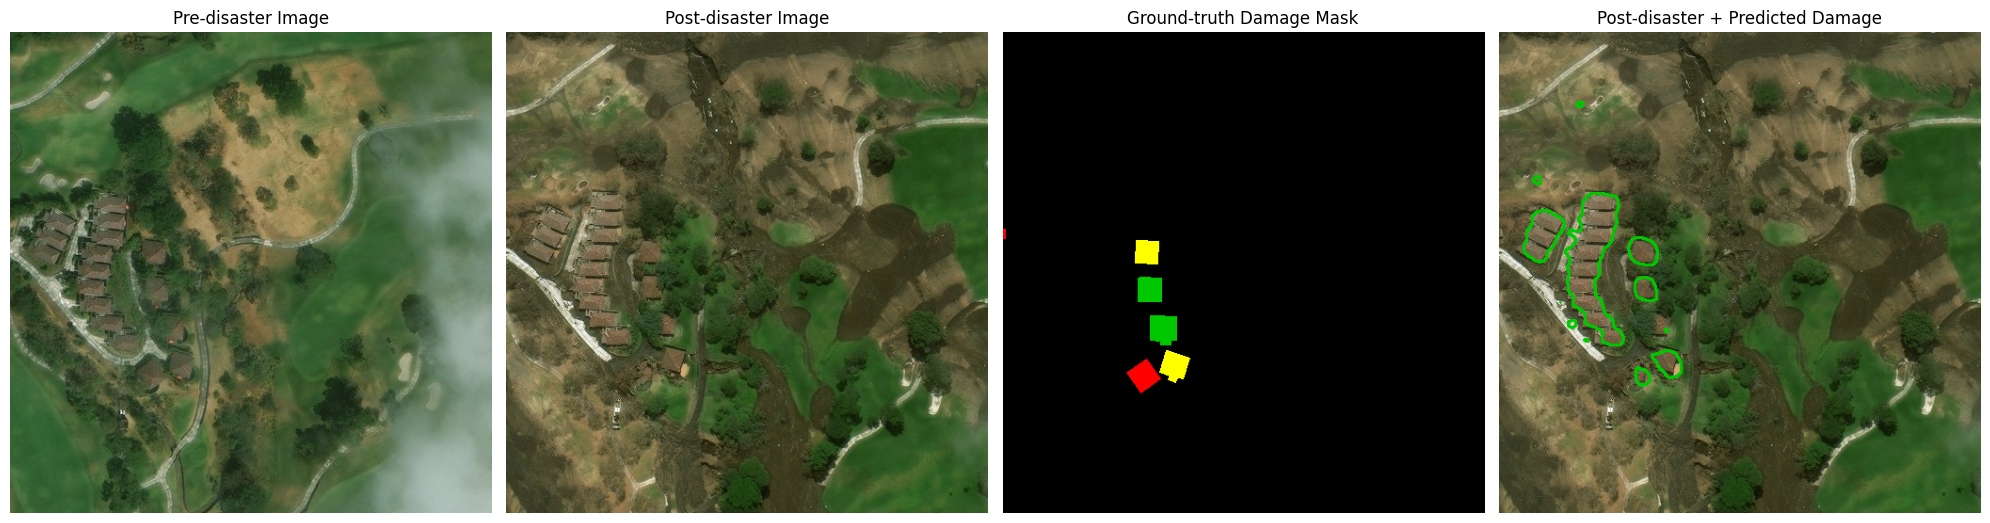

In [ ]:

# Load the best trained model
if not os.path.exists(BEST_CKPT):
    raise FileNotFoundError(f"Best checkpoint not found: {BEST_CKPT}")

best_payload = torch.load(
    BEST_CKPT,
    map_location='cpu',
    weights_only=False
)

model.load_state_dict(best_payload['model_state_dict'])
model.to(device)
model.eval()

# Select one validation sample
pre_tensor, post_tensor, true_mask = val_ds[0]

# Generate prediction
with torch.no_grad():
    with torch.autocast(
        device_type=device.type,
        dtype=torch.float16,
        enabled=(device.type == 'cuda')
    ):
        logits = model(
            pre_tensor.unsqueeze(0).to(device),
            post_tensor.unsqueeze(0).to(device)
        )

pred_mask = logits.argmax(1)[0].cpu().numpy().astype(np.uint8)

# Convert normalized images back to display format
pre_vis = np.clip(
    (pre_tensor.numpy().transpose(1, 2, 0) * STD + MEAN) * 255,
    0, 255
).astype(np.uint8)

post_vis = np.clip(
    (post_tensor.numpy().transpose(1, 2, 0) * STD + MEAN) * 255,
    0, 255
).astype(np.uint8)

# Ground-truth mask
true_np = true_mask.numpy()

true_vis = CLASS_COLORS[
    np.where(true_np <= 4, true_np, 0)
]

# Create prediction overlay on the post-disaster image
overlay = post_vis.copy()

DAMAGE_COLORS = {
    1: (0, 200, 0),      # No damage - Green
    2: (255, 220, 0),    # Minor damage - Yellow
    3: (255, 120, 0),   # Major damage - Orange
    4: (230, 0, 0)      # Destroyed - Red
}

# Draw predicted damage-class contours
for class_id, color in DAMAGE_COLORS.items():
    class_mask = (pred_mask == class_id).astype(np.uint8)

    contours, _ = cv2.findContours(
        class_mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cv2.drawContours(
        overlay,
        contours,
        -1,
        color,
        2
    )

# Display all four images
fig, axes = plt.subplots(1, 4, figsize=(20, 6))

images = [
    pre_vis,
    post_vis,
    true_vis,
    overlay
]

titles = [
    'Pre-disaster Image',
    'Post-disaster Image',
    'Ground-truth Damage Mask',
    'Post-disaster + Predicted Damage'
]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()


## 19. Download and extract a small, separate test subset

**What this cell does:** downloads only one test shard (not all six) and extracts up to 120 samples using the same lossless-mask/JPEG-image procedure. The test set is separate from training and validation. Its files also remain in Colab temporary storage, not Drive.

In [ ]:
TEST_PARQUETS = download_shards('test', TEST_SHARD_IDS, 6)
test_bad_rows = extract_compressed(TEST_PARQUETS, TEST_ROOT, MAX_TEST_SAMPLES, 'test')
print('Test samples:', len(get_sample_names(TEST_ROOT)))
!du -sh /content/xbd_small
!df -h /content | tail -1

data/test-00000-of-00006.parquet: reconstructing file:   0%|          |  0.00B /  465MB            

data/test-00000-of-00006.parquet: downloading bytes:           |  0.00B            

/tmp/ipykernel_431/433869292.py:39: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(mask.astype(np.uint8), mode='L').save(


test: 120 complete samples; newly written 120; rejected rows 0
Test samples: 120
267M	/content/xbd_small
overlay         113G  2.5G  111G   3% /


## 20. Audit the test subset

**What this cell does:** applies the same file-pairing, image-size, mask-channel, and class-ID checks to the test subset before calculating test metrics.

In [ ]:
test_label_counts = audit_split(TEST_ROOT, 'test')
test_ds = XBDDataset(TEST_ROOT, train=False, crop_size=CROP_SIZE)
test_dl = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                     num_workers=NUM_WORKERS, pin_memory=(device.type == 'cuda'))
print('Test samples loaded:', len(test_ds))

--- test audit ---
Samples: 120 | issues: 0
Label pixel counts: {0: 120365439, 1: 3173491, 2: 685426, 3: 998743, 4: 606021}
Unexpected label values: []
Test samples loaded: 120


## 20A. Free temporary test-shard space

**What this cell does:** removes the downloaded test Parquet shard after the extracted test images and masks have passed the audit. The test images/masks remain in Colab temporary storage for evaluation.

In [ ]:
for parquet_path in TEST_PARQUETS:
    if os.path.exists(parquet_path):
        os.remove(parquet_path)
print('Removed downloaded test Parquet shard from temporary storage.')
!du -sh /content/xbd_small
!df -h /content | tail -1

Removed downloaded test Parquet shard from temporary storage.
267M	/content/xbd_small
overlay         113G  2.1G  111G   2% /


## 21. Final test evaluation

**What this cell does:** evaluates the best validation checkpoint on the held-out test subset without updating any weights. It reports pixel-level F1 for each class, mean damage F1 for classes 1–4, and a row-normalized confusion matrix. Since this is a small subset, label the result as a pilot test-subset metric.

In [ ]:
model.load_state_dict(torch.load(BEST_CKPT, map_location='cpu', weights_only=False)['model_state_dict'])
model.to(device).eval()
test_cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)
with torch.no_grad():
    for pre, post, masks in tqdm(test_dl, desc='Test evaluation'):
        pre = pre.to(device, non_blocking=True)
        post = post.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=(device.type == 'cuda')):
            predictions = model(pre, post).argmax(dim=1)
        test_cm += confusion_matrix(predictions, masks)

test_f1 = f1_from_confusion(test_cm)
print('PILOT TEST-SUBSET RESULTS (pixel-level F1)')
for name, score in zip(CLASS_NAMES, test_f1):
    print(f'{name:14s}: {score:.4f}')
print('Mean damage F1 (classes 1–4):', round(float(test_f1[1:].mean()), 4))
print('Row-normalized confusion matrix (rows=true, columns=predicted):')
print(np.round((test_cm.float() / test_cm.sum(1, keepdim=True).clamp(min=1)).numpy(), 3))

Test evaluation:   0%|          | 0/60 [00:00<?, ?it/s]

PILOT TEST-SUBSET RESULTS (pixel-level F1)
background    : 0.9881
no damage     : 0.5526
minor damage  : 0.0000
major damage  : 0.0000
destroyed     : 0.4707
Mean damage F1 (classes 1–4): 0.2558
Row-normalized confusion matrix (rows=true, columns=predicted):
[[0.988 0.011 0.    0.    0.001]
 [0.25  0.737 0.    0.    0.013]
 [0.329 0.65  0.    0.    0.021]
 [0.233 0.728 0.    0.    0.039]
 [0.276 0.262 0.    0.    0.462]]


## 22. Visualize a test prediction

**What this cell does:** shows one test sample's post-disaster image, ground-truth mask, and model prediction. It is useful for visually checking the model on data that was not used for training or validation.

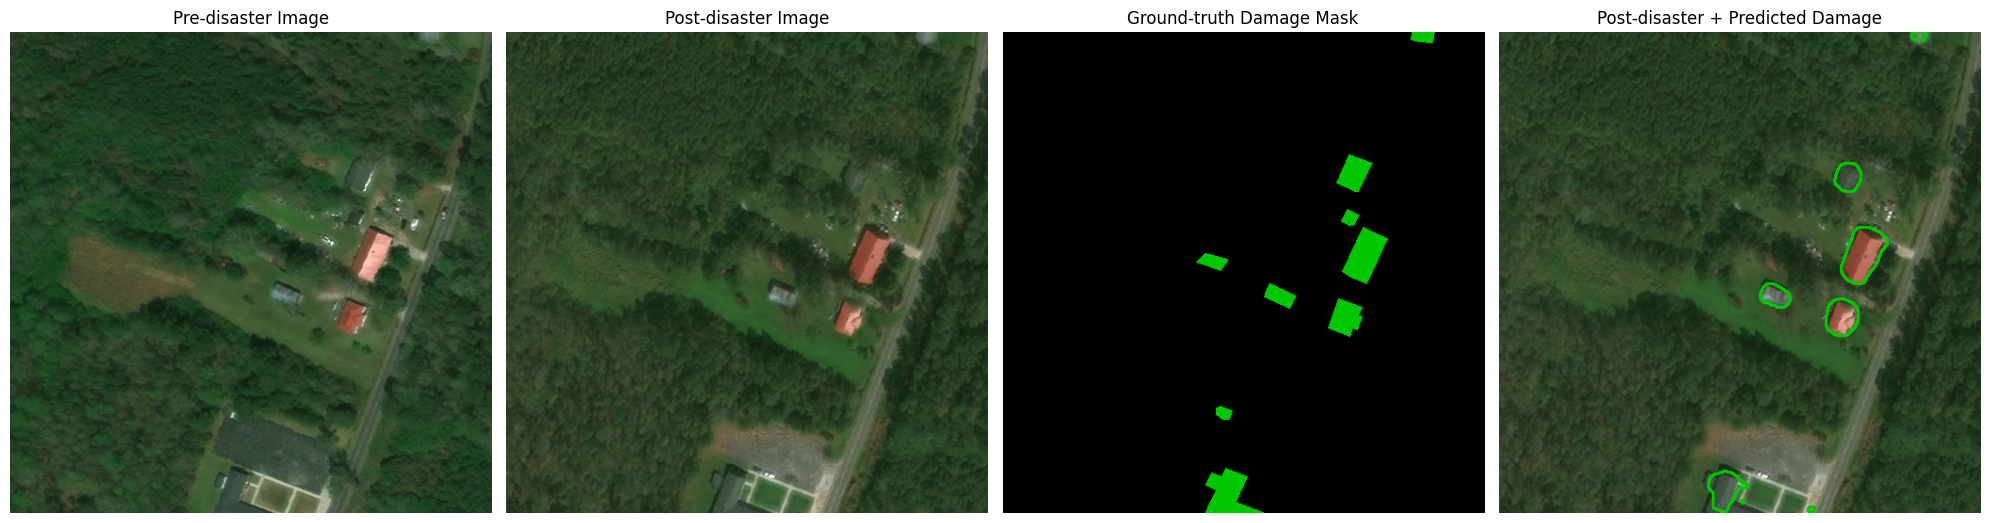

In [ ]:

# Select one test sample
pre_tensor, post_tensor, true_mask = test_ds[10]

# Generate model prediction
with torch.no_grad():
    with torch.autocast(
        device_type=device.type,
        dtype=torch.float16,
        enabled=(device.type == 'cuda')
    ):
        logits = model(
            pre_tensor.unsqueeze(0).to(device),
            post_tensor.unsqueeze(0).to(device)
        )

pred_mask = logits.argmax(1)[0].cpu().numpy().astype(np.uint8)

# Convert images back to display format
pre_vis = np.clip(
    (pre_tensor.numpy().transpose(1, 2, 0) * STD + MEAN) * 255,
    0, 255
).astype(np.uint8)

post_vis = np.clip(
    (post_tensor.numpy().transpose(1, 2, 0) * STD + MEAN) * 255,
    0, 255
).astype(np.uint8)

# Ground-truth mask
true_np = true_mask.numpy()

true_vis = CLASS_COLORS[
    np.where(true_np <= 4, true_np, 0)
]

# Create predicted damage overlay
overlay = post_vis.copy()

DAMAGE_COLORS = {
    1: (0, 200, 0),
    2: (255, 220, 0),
    3: (255, 120, 0),
    4: (230, 0, 0)
}

for class_id, color in DAMAGE_COLORS.items():
    class_mask = (pred_mask == class_id).astype(np.uint8)

    contours, _ = cv2.findContours(
        class_mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cv2.drawContours(overlay, contours, -1, color, 2)

# Display four panels
fig, axes = plt.subplots(1, 4, figsize=(20, 6))

images = [
    pre_vis,
    post_vis,
    true_vis,
    overlay
]

titles = [
    'Pre-disaster Image',
    'Post-disaster Image',
    'Ground-truth Damage Mask',
    'Post-disaster + Predicted Damage'
]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()


## 23. Export the Streamlit frontend and model files to Google Drive

**What this cell does:** writes a reusable `model_def.py`, a complete `app.py`, `requirements.txt`, and a README into your Drive project folder. The Streamlit app accepts a pre-disaster and post-disaster image, runs sliding-window inference using the trained model, shows the predicted mask and overlay, reports pixel-area percentages for the four building classes, and lets the user download the mask and overlay.

The app code is exported without copying the checkpoint again. The trained best checkpoint remains in `checkpoints/resnet50_damage_best.pt`, keeping Drive usage lower. For local use, download the app folder and the best checkpoint, then place the checkpoint in the app's `checkpoints` subfolder.

## 23. Export Streamlit application files

**What this cell does:** creates `app.py`, `model_def.py`, `requirements.txt`, and `README.md` in Google Drive and packages the source code into a ZIP. It does not duplicate the trained checkpoint, so it avoids using extra Drive space. Download the best checkpoint separately and place it in the app's `checkpoints/` folder when setting up the app locally.

In [ ]:
from pathlib import Path
import zipfile, os

app_dir = Path(APP_DIR)
(app_dir / "checkpoints").mkdir(parents=True, exist_ok=True)
(app_dir / "app.py").write_text('import os\nimport io\nimport numpy as np\nimport streamlit as st\nimport torch\nfrom PIL import Image\nfrom model_def import SiamUNet\n\nst.set_page_config(page_title="Building Damage Assessment", page_icon="🏚️", layout="wide")\nCLASS_NAMES = ["Background", "No damage", "Minor damage", "Major damage", "Destroyed"]\nCOLORS = np.array([[0,0,0], [0,200,0], [255,255,0], [255,140,0], [255,0,0]], dtype=np.uint8)\nMEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)\nSTD = np.array([0.229, 0.224, 0.225], dtype=np.float32)\nTILE = 512\nOVERLAP = 128\n\n@st.cache_resource\ndef load_model(checkpoint_path):\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n    model = SiamUNet(encoder_name="resnet50", num_classes=5, encoder_weights=None)\n    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)\n    state = checkpoint["model_state_dict"] if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint else checkpoint\n    model.load_state_dict(state)\n    model.to(device).eval()\n    return model, device\n\ndef tile_starts(length, tile, stride):\n    if length <= tile:\n        return [0]\n    starts = list(range(0, length - tile + 1, stride))\n    last = length - tile\n    if starts[-1] != last:\n        starts.append(last)\n    return starts\n\ndef predict_mask(pre_rgb, post_rgb, model, device):\n    if pre_rgb.shape != post_rgb.shape:\n        raise ValueError("Pre-disaster and post-disaster images must have identical dimensions.")\n    h, w = pre_rgb.shape[:2]\n    pad_h, pad_w = max(0, TILE-h), max(0, TILE-w)\n    if pad_h or pad_w:\n        pre_rgb = np.pad(pre_rgb, ((0,pad_h),(0,pad_w),(0,0)), mode="edge")\n        post_rgb = np.pad(post_rgb, ((0,pad_h),(0,pad_w),(0,0)), mode="edge")\n    H, W = pre_rgb.shape[:2]\n    stride = TILE - OVERLAP\n    ys, xs = tile_starts(H, TILE, stride), tile_starts(W, TILE, stride)\n    logits_sum = np.zeros((5, H, W), dtype=np.float32)\n    weights = np.zeros((H, W), dtype=np.float32)\n    with torch.no_grad():\n        for y in ys:\n            for x in xs:\n                pre = pre_rgb[y:y+TILE, x:x+TILE].astype(np.float32) / 255.0\n                post = post_rgb[y:y+TILE, x:x+TILE].astype(np.float32) / 255.0\n                pre = torch.from_numpy(((pre-MEAN)/STD).transpose(2,0,1).copy()).unsqueeze(0).to(device)\n                post = torch.from_numpy(((post-MEAN)/STD).transpose(2,0,1).copy()).unsqueeze(0).to(device)\n                with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=(device.type == "cuda")):\n                    logits = model(pre, post)[0].float().cpu().numpy()\n                logits_sum[:, y:y+TILE, x:x+TILE] += logits\n                weights[y:y+TILE, x:x+TILE] += 1.0\n    averaged = logits_sum / np.maximum(weights[None, :, :], 1e-6)\n    return averaged.argmax(axis=0)[:h, :w].astype(np.uint8)\n\ndef png_bytes(array, mode=None):\n    image = Image.fromarray(array, mode=mode)\n    buffer = io.BytesIO()\n    image.save(buffer, format="PNG")\n    return buffer.getvalue()\n\nst.title("Building Damage Assessment")\nst.caption("ResNet50 Siamese U-Net · Pre- and post-disaster satellite imagery")\nst.info("Upload a matching pair of satellite images. The model predicts pixel-level damage classes; it does not guarantee exact building counts.")\n\ncheckpoint_path = os.path.join(os.path.dirname(__file__), "checkpoints", "resnet50_damage_best.pt")\nif not os.path.exists(checkpoint_path):\n    st.error("Model checkpoint not found. Put resnet50_damage_best.pt inside the app\'s checkpoints/ folder.")\n    st.stop()\n\npre_file = st.file_uploader("Pre-disaster image", type=["png", "jpg", "jpeg"], key="pre")\npost_file = st.file_uploader("Post-disaster image", type=["png", "jpg", "jpeg"], key="post")\nif pre_file is not None and post_file is not None:\n    pre_image = Image.open(pre_file).convert("RGB")\n    post_image = Image.open(post_file).convert("RGB")\n    if pre_image.size != post_image.size:\n        st.error(f"Image dimensions must match. Pre: {pre_image.size}; post: {post_image.size}.")\n        st.stop()\n    col1, col2 = st.columns(2)\n    col1.image(pre_image, caption="Pre-disaster", use_container_width=True)\n    col2.image(post_image, caption="Post-disaster", use_container_width=True)\n    if st.button("Analyze building damage", type="primary", use_container_width=True):\n        try:\n            model, device = load_model(checkpoint_path)\n            with st.spinner("Analyzing image tiles..."):\n                prediction = predict_mask(np.array(pre_image), np.array(post_image), model, device)\n            color_mask = COLORS[prediction]\n            overlay = (0.55 * color_mask + 0.45 * np.array(post_image)).clip(0,255).astype(np.uint8)\n            total_pixels = prediction.size\n            counts = np.bincount(prediction.ravel(), minlength=5)\n            st.subheader("Damage assessment")\n            a, b = st.columns(2)\n            a.image(color_mask, caption="Predicted damage mask", use_container_width=True)\n            b.image(overlay, caption="Prediction overlay", use_container_width=True)\n            st.subheader("Predicted pixel-area distribution")\n            for class_id in range(1,5):\n                percentage = 100.0 * counts[class_id] / max(total_pixels,1)\n                st.write(f"**{CLASS_NAMES[class_id]}:** {percentage:.2f}%")\n                st.progress(float(percentage/100.0))\n            c1, c2 = st.columns(2)\n            c1.download_button("Download class-ID mask (PNG)", png_bytes(prediction, mode="L"),\n                               file_name="predicted_damage_mask.png", mime="image/png")\n            c2.download_button("Download colour overlay (PNG)", png_bytes(overlay, mode="RGB"),\n                               file_name="damage_overlay.png", mime="image/png")\n            st.caption("Percentages represent image pixels, not the number of buildings. Predictions are decision-support outputs and should be reviewed by a qualified person.")\n        except Exception as exc:\n            st.exception(exc)\nelse:\n    st.warning("Upload both images to enable damage assessment.")\n', encoding="utf-8")
(app_dir / "model_def.py").write_text('import torch\nimport torch.nn as nn\nimport torch.nn.functional as F\nimport segmentation_models_pytorch as smp\n\ndef conv_block(in_channels, out_channels):\n    return nn.Sequential(\n        nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),\n        nn.BatchNorm2d(out_channels),\n        nn.ReLU(inplace=True),\n        nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),\n        nn.BatchNorm2d(out_channels),\n        nn.ReLU(inplace=True)\n    )\n\nclass SiamUNet(nn.Module):\n    def __init__(self, encoder_name="resnet50", num_classes=5, encoder_weights=None):\n        super().__init__()\n        self.encoder = smp.encoders.get_encoder(encoder_name, in_channels=3, depth=5, weights=encoder_weights)\n        channels = self.encoder.out_channels\n        self.fuse = nn.ModuleList([nn.Conv2d(3 * channels[i], channels[i], kernel_size=1) for i in range(1, 6)])\n        decoder_channels = [256, 128, 64, 32]\n        self.decoder = nn.ModuleList()\n        previous_channels = channels[5]\n        for skip_channels, out_channels in zip([channels[4], channels[3], channels[2], channels[1]], decoder_channels):\n            self.decoder.append(conv_block(previous_channels + skip_channels, out_channels))\n            previous_channels = out_channels\n        self.segmentation_head = nn.Sequential(conv_block(previous_channels, 32), nn.Conv2d(32, num_classes, kernel_size=1))\n\n    def forward(self, pre, post):\n        pre_features = self.encoder(pre)\n        post_features = self.encoder(post)\n        fused = []\n        for i in range(1, 6):\n            difference = torch.abs(post_features[i] - pre_features[i])\n            combined = torch.cat([pre_features[i], post_features[i], difference], dim=1)\n            fused.append(self.fuse[i - 1](combined))\n        x = fused[4]\n        for j, decoder_block in enumerate(self.decoder):\n            x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)\n            x = decoder_block(torch.cat([x, fused[3 - j]], dim=1))\n        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)\n        return self.segmentation_head(x)\n', encoding="utf-8")
(app_dir / "requirements.txt").write_text('streamlit>=1.35\ntorch>=2.2\ntorchvision>=0.17\nsegmentation-models-pytorch>=0.3.3\nnumpy>=1.24\nPillow>=10\n', encoding="utf-8")
(app_dir / "README.md").write_text('# Building Damage Assessment — Streamlit app\n\n## Files\n- `app.py`: Streamlit user interface and sliding-window inference\n- `model_def.py`: ResNet50 Siamese U-Net architecture\n- `requirements.txt`: Python dependencies\n- `checkpoints/resnet50_damage_best.pt`: copy the trained best checkpoint here\n\n## Run locally\n1. Create a Python environment (Python 3.10 or 3.11 recommended).\n2. Install dependencies: `pip install -r requirements.txt`\n3. Put `resnet50_damage_best.pt` in `checkpoints/`.\n4. Run: `streamlit run app.py`\n\nThe app expects a matching pre-disaster and post-disaster image. It uses 512-pixel sliding-window inference with overlap. The dashboard reports pixel-area percentages, not verified building counts.\n', encoding="utf-8")
zip_path = os.path.join(PROJECT_DRIVE, "streamlit_app_source.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for file_path in app_dir.rglob("*"):
        if file_path.is_file():
            zf.write(file_path, file_path.relative_to(app_dir))
print("Streamlit files saved to:", app_dir)
print("Source ZIP:", zip_path)
print("Best model checkpoint remains at:", BEST_CKPT)
print("After downloading the app ZIP, download the best checkpoint separately and put it in the app's checkpoints/ folder.")

Streamlit files saved to: /content/drive/MyDrive/Building_Damage_ResNet50/streamlit_app
Source ZIP: /content/drive/MyDrive/Building_Damage_ResNet50/streamlit_app_source.zip
Best model checkpoint remains at: /content/drive/MyDrive/Building_Damage_ResNet50/checkpoints/resnet50_damage_best.pt
After downloading the app ZIP, download the best checkpoint separately and put it in the app's checkpoints/ folder.


In [ ]:
import ast
from pathlib import Path

for filename in ["app.py", "model_def.py"]:
    file_path = Path(APP_DIR) / filename

    ast.parse(file_path.read_text(encoding="utf-8"))

    print(filename, "syntax OK")

app.py syntax OK
model_def.py syntax OK


## 24. Final project and storage check

**What this cell does:** reports the final model/checkpoint paths, the size of the temporary dataset, and the files generated for Streamlit. The dataset lives in Colab temporary storage and can disappear after a runtime reset; checkpoints and exported app source remain in Google Drive.

In [ ]:
print('Best checkpoint:', BEST_CKPT, '| exists:', os.path.exists(BEST_CKPT))
print('Latest checkpoint:', LATEST_CKPT, '| exists:', os.path.exists(LATEST_CKPT))
print('Streamlit app folder:', APP_DIR)
print('Streamlit source ZIP:', os.path.join(PROJECT_DRIVE, 'streamlit_app_source.zip'))
print('Temporary dataset folder:', DATA_DIR)
!du -sh /content/xbd_small /content/xbd_parquet_subset 2>/dev/null
!du -sh /content/drive/MyDrive/Building_Damage_ResNet50
!df -h /content | tail -1

Best checkpoint: /content/drive/MyDrive/Building_Damage_ResNet50/checkpoints/resnet50_damage_best.pt | exists: True
Latest checkpoint: /content/drive/MyDrive/Building_Damage_ResNet50/checkpoints/resnet50_damage_latest.pt | exists: True
Streamlit app folder: /content/drive/MyDrive/Building_Damage_ResNet50/streamlit_app
Streamlit source ZIP: /content/drive/MyDrive/Building_Damage_ResNet50/streamlit_app_source.zip
Temporary dataset folder: /content/xbd_small
267M	/content/xbd_small
48K	/content/xbd_parquet_subset
960M	/content/drive/MyDrive/Building_Damage_ResNet50
overlay         113G  2.1G  111G   2% /


In [ ]:
import shutil
from pathlib import Path

APP_CHECKPOINT_DIR = Path(APP_DIR) / "checkpoints"
APP_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

APP_CHECKPOINT = APP_CHECKPOINT_DIR / "resnet50_damage_best.pt"

shutil.copy2(BEST_CKPT, APP_CHECKPOINT)

print("Checkpoint copied:", APP_CHECKPOINT.exists())
print("Checkpoint size (MB):", round(APP_CHECKPOINT.stat().st_size / (1024**2), 2))

Checkpoint copied: True
Checkpoint size (MB): 188.26


In [ ]:
import zipfile
from pathlib import Path

APP_DIR = Path(APP_DIR)
zip_path = Path(PROJECT_DRIVE) / "streamlit_app_source.zip"

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for file_path in APP_DIR.rglob("*"):
        if file_path.is_file():
            zf.write(file_path, file_path.relative_to(APP_DIR))

print("Final ZIP created:", zip_path)
print("ZIP size (MB):", round(zip_path.stat().st_size / (1024**2), 2))

with zipfile.ZipFile(zip_path, "r") as zf:
    print("\nZIP contents:")
    for name in zf.namelist():
        print(name)

Final ZIP created: /content/drive/MyDrive/Building_Damage_ResNet50/streamlit_app_source.zip
ZIP size (MB): 174.21

ZIP contents:
app.py
model_def.py
requirements.txt
README.md
checkpoints/resnet50_damage_best.pt


In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(APP_DIR))

from model_def import SiamUNet

app_model = SiamUNet(num_classes=5)

checkpoint = torch.load(
    APP_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

app_model.load_state_dict(checkpoint["model_state_dict"])

print("Checkpoint loaded successfully!")
print("Model architecture:", type(app_model).__name__)
print("Number of classes:", 5)

Checkpoint loaded successfully!
Model architecture: SiamUNet
Number of classes: 5


In [ ]:
import numpy as np
import torch

app_model.eval()

sample_pre, sample_post, sample_mask = test_ds[0]

with torch.no_grad():
    pre = sample_pre.unsqueeze(0)
    post = sample_post.unsqueeze(0)

    with torch.autocast(
        device_type=device.type,
        dtype=torch.float16,
        enabled=(device.type == "cuda")
    ):
        output = app_model(pre, post)

    prediction = output.argmax(dim=1).squeeze(0).cpu().numpy()

print("Prediction shape:", prediction.shape)
print("Unique predicted classes:", np.unique(prediction))
print("Prediction successful:", prediction.shape == (512, 512))

Prediction shape: (512, 512)
Unique predicted classes: [0 1 4]
Prediction successful: True


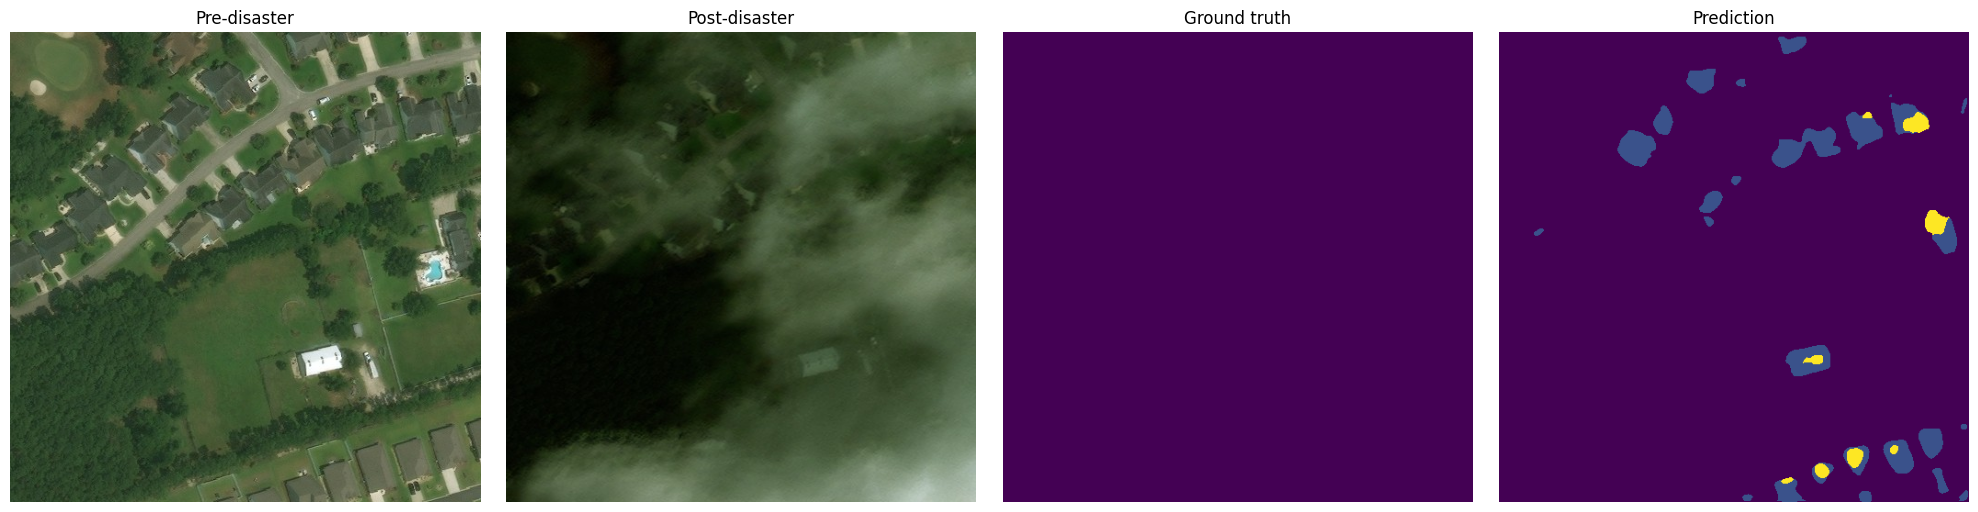

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Denormalize helper (adjust mean/std if you used different values)
mean = np.array([0.485, 0.456, 0.406])
std  = np.array([0.229, 0.224, 0.225])

def denorm(t):
    img = t.cpu().numpy().transpose(1, 2, 0)
    img = img * std + mean
    return np.clip(img, 0, 1)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(denorm(sample_pre));  axes[0].set_title("Pre-disaster")
axes[1].imshow(denorm(sample_post)); axes[1].set_title("Post-disaster")

gt = sample_mask.cpu().numpy()
if gt.ndim == 3:          # if one-hot, collapse to class index
    gt = gt.argmax(0)
axes[2].imshow(gt, cmap="viridis", vmin=0, vmax=4)
axes[2].set_title("Ground truth")

axes[3].imshow(prediction, cmap="viridis", vmin=0, vmax=4)
axes[3].set_title("Prediction")

for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# How much of the GT is non-background?
gt_non_bg = (gt != 0).mean() * 100
print(f"GT: {gt_non_bg:.2f}% of pixels are NOT background")

# How much of the prediction is non-background?
pred_non_bg = (prediction != 0).mean() * 100
print(f"Prediction: {pred_non_bg:.2f}% of pixels are NOT background")

# Full class distribution in prediction
classes, counts = np.unique(prediction, return_counts=True)
total = prediction.size
for c, n in zip(classes, counts):
    print(f"  Class {c}: {n/total*100:.2f}%")

GT: 0.00% of pixels are NOT background
Prediction: 5.09% of pixels are NOT background
  Class 0: 94.91%
  Class 1: 4.41%
  Class 4: 0.69%


In [ ]:
# Find the index of a test sample that has real damage in the GT
app_model.eval()
target_idx = None

for i in range(len(test_ds)):
    _, _, mask_s = test_ds[i]
    gt_i = mask_s.cpu().numpy()
    if gt_i.ndim == 3:
        gt_i = gt_i.argmax(0)
    frac_damaged = (gt_i != 0).mean()
    if frac_damaged > 0.10:          # at least 10% damaged pixels
        print(f"Index {i}: {frac_damaged*100:.1f}% damaged")
        target_idx = i
        break

if target_idx is None:
    print("⚠️ No sample with >10% damage found in the first pass.")
else:
    print(f"✅ Using index {target_idx}")

Index 2: 13.3% damaged
✅ Using index 2


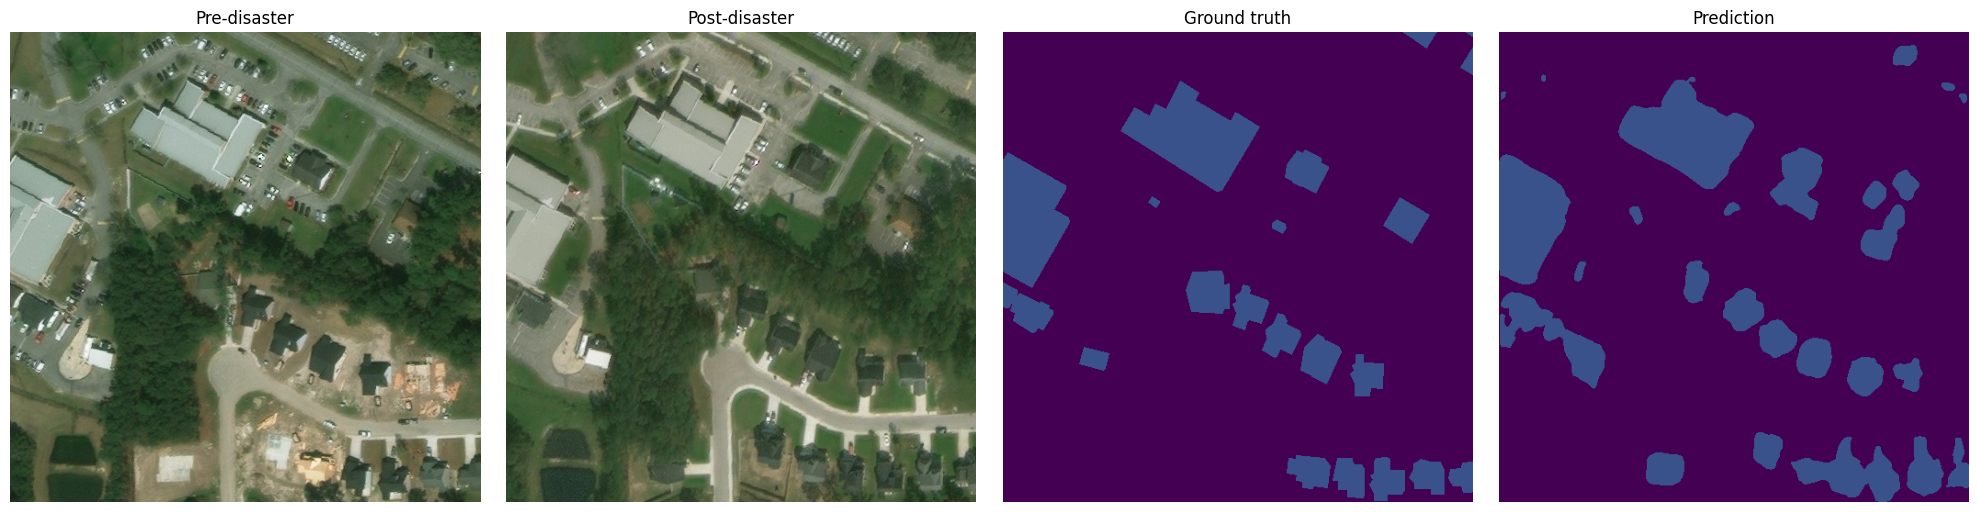

GT non-bg:   13.27%
Pred non-bg: 16.92%
Pred class distribution:
  Class 0: 83.08%
  Class 1: 16.92%


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

mean = np.array([0.485, 0.456, 0.406])
std  = np.array([0.229, 0.224, 0.225])

def denorm(t):
    img = t.cpu().numpy().transpose(1, 2, 0)
    img = img * std + mean
    return np.clip(img, 0, 1)

# ---- use the damaged sample ----
sample_pre, sample_post, sample_mask = test_ds[2]

app_model = app_model.to(device)      # <-- ADD THIS LINE
app_model.eval()

with torch.no_grad():
    pre  = sample_pre.unsqueeze(0).to(device)
    post = sample_post.unsqueeze(0).to(device)
    output = app_model(pre, post)
    prediction = output.argmax(dim=1).squeeze(0).cpu().numpy()

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(denorm(sample_pre));  axes[0].set_title("Pre-disaster")
axes[1].imshow(denorm(sample_post)); axes[1].set_title("Post-disaster")

gt = sample_mask.cpu().numpy()
if gt.ndim == 3:
    gt = gt.argmax(0)

axes[2].imshow(gt, cmap="viridis", vmin=0, vmax=4)
axes[2].set_title("Ground truth")

axes[3].imshow(prediction, cmap="viridis", vmin=0, vmax=4)
axes[3].set_title("Prediction")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

print(f"GT non-bg:   {(gt != 0).mean()*100:.2f}%")
print(f"Pred non-bg: {(prediction != 0).mean()*100:.2f}%")
print("Pred class distribution:")
for c, n in zip(*np.unique(prediction, return_counts=True)):
    print(f"  Class {c}: {n/prediction.size*100:.2f}%")

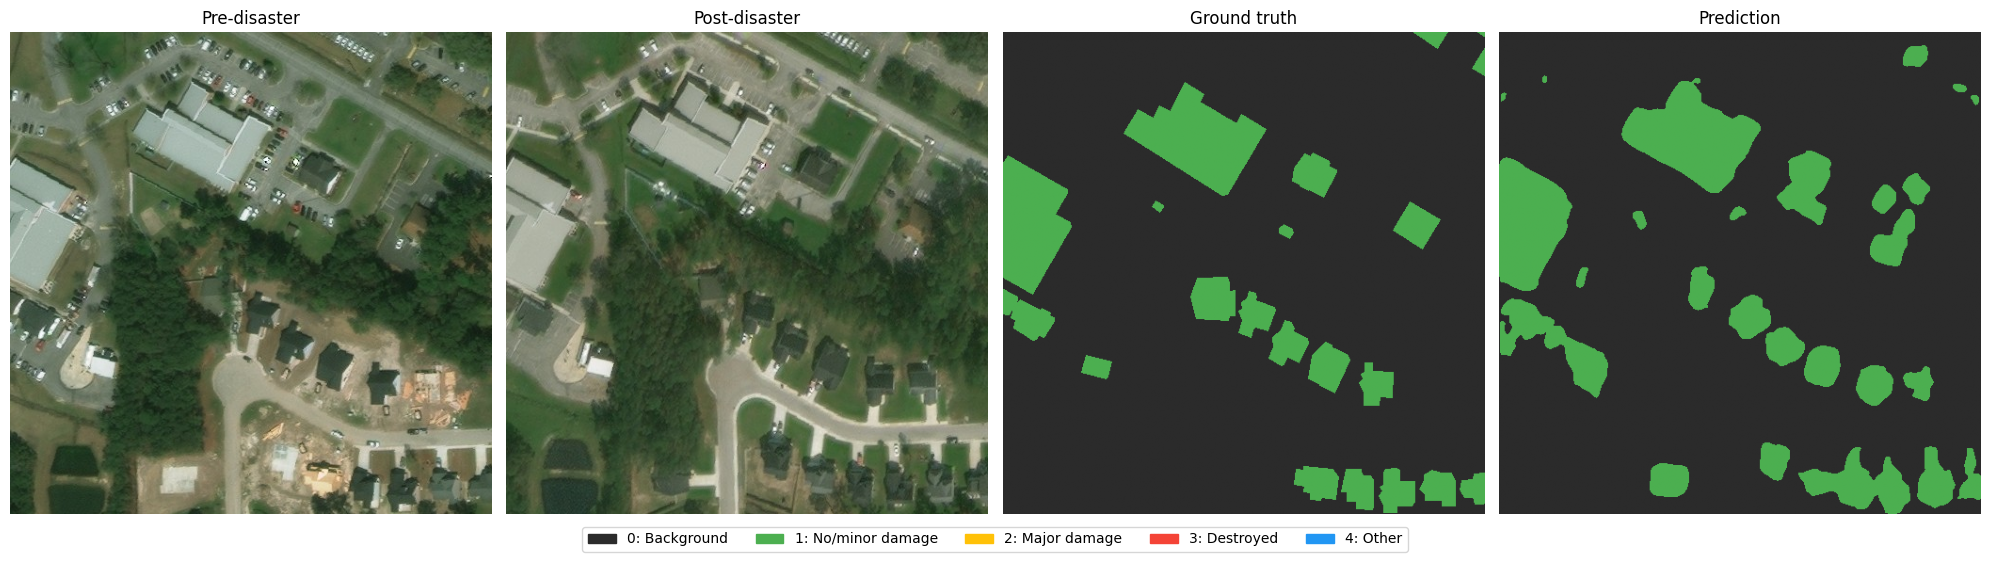


Class distribution comparison:
Class                     GT %    Pred %
0: Background           86.73%    83.08%
1: No/minor damage      13.27%    16.92%
2: Major damage          0.00%     0.00%
3: Destroyed             0.00%     0.00%
4: Other                 0.00%     0.00%


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# --- Custom colormap: one clear color per class ---
from matplotlib.colors import ListedColormap

CLASS_NAMES = ["0: Background", "1: No/minor damage", "2: Major damage", "3: Destroyed", "4: Other"]
CLASS_COLORS = [
    "#2b2b2b",   # 0 background  -> dark gray
    "#4CAF50",   # 1 minor       -> green
    "#FFC107",   # 2 major       -> amber
    "#F44336",   # 3 destroyed   -> red
    "#2196F3",   # 4 other       -> blue
]
cmap = ListedColormap(CLASS_COLORS)

# --- Get the sample ---
sample_pre, sample_post, sample_mask = test_ds[2]

app_model = app_model.to(device)
app_model.eval()
with torch.no_grad():
    pre  = sample_pre.unsqueeze(0).to(device)
    post = sample_post.unsqueeze(0).to(device)
    output = app_model(pre, post)
    prediction = output.argmax(dim=1).squeeze(0).cpu().numpy()

gt = sample_mask.cpu().numpy()
if gt.ndim == 3:
    gt = gt.argmax(0)

# --- Denorm helper ---
mean = np.array([0.485, 0.456, 0.406])
std  = np.array([0.229, 0.224, 0.225])
def denorm(t):
    img = t.cpu().numpy().transpose(1, 2, 0)
    return np.clip(img * std + mean, 0, 1)

# --- Plot ---
fig, axes = plt.subplots(1, 4, figsize=(20, 5.5))

axes[0].imshow(denorm(sample_pre));  axes[0].set_title("Pre-disaster")
axes[1].imshow(denorm(sample_post)); axes[1].set_title("Post-disaster")
axes[2].imshow(gt,         cmap=cmap, vmin=0, vmax=4); axes[2].set_title("Ground truth")
axes[3].imshow(prediction, cmap=cmap, vmin=0, vmax=4); axes[3].set_title("Prediction")

for ax in axes:
    ax.axis("off")

# --- Legend ---
patches = [mpatches.Patch(color=c, label=n) for c, n in zip(CLASS_COLORS, CLASS_NAMES)]
fig.legend(handles=patches, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout()
plt.show()

# --- Class distribution comparison ---
print("\nClass distribution comparison:")
print(f"{'Class':<22}{'GT %':>8}{'Pred %':>10}")
for c in range(5):
    gt_pct   = (gt == c).mean() * 100
    pred_pct = (prediction == c).mean() * 100
    print(f"{CLASS_NAMES[c]:<22}{gt_pct:>7.2f}%{pred_pct:>9.2f}%")

In [ ]:
# Check GT class distribution across the entire test set
from collections import Counter
counter = Counter()
app_model.eval()

with torch.no_grad():
    for i in range(len(test_ds)):
        _, _, m = test_ds[i]
        m = m.cpu().numpy()
        if m.ndim == 3:
            m = m.argmax(0)
        for c in np.unique(m):
            counter[int(c)] += int((m == c).sum())

total = sum(counter.values())
print("GT class distribution across full test set:")
for c in sorted(counter):
    print(f"  Class {c}: {counter[c]/total*100:.3f}% of all pixels")

GT class distribution across full test set:
  Class 0: 95.716% of all pixels
  Class 1: 2.352% of all pixels
  Class 2: 0.598% of all pixels
  Class 3: 0.902% of all pixels
  Class 4: 0.432% of all pixels


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for f in files:
        if f.endswith((".pth", ".pt", ".ckpt")):
            full = os.path.join(root, f)
            size_mb = os.path.getsize(full) / 1e6
            print(f"{full}   ({size_mb:.1f} MB)")

/content/drive/MyDrive/Building_Damage_ResNet50/checkpoints/resnet50_damage_latest.pt   (591.7 MB)
/content/drive/MyDrive/Building_Damage_ResNet50/checkpoints/resnet50_damage_best.pt   (197.4 MB)
/content/drive/MyDrive/Building_Damage_ResNet50/streamlit_app/checkpoints/resnet50_damage_best.pt   (197.4 MB)


In [ ]:
import torch

ckpt_path = "/content/drive/MyDrive/Building_Damage_ResNet50/streamlit_app/checkpoints/resnet50_damage_best.pt"
ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)

print("Type of checkpoint:", type(ckpt))
if isinstance(ckpt, dict):
    print("Top-level keys:", list(ckpt.keys())[:10])
    # Common patterns:
    for k in ("model_state_dict", "state_dict", "model", "weights", "epoch", "best_iou", "val_iou"):
        if k in ckpt:
            v = ckpt[k]
            if isinstance(v, dict):
                print(f"  '{k}' is a dict with {len(v)} tensors")
            else:
                print(f"  '{k}' = {v}")

Type of checkpoint: <class 'dict'>
Top-level keys: ['model_state_dict', 'best_val_damage_f1', 'class_names', 'crop_size', 'encoder']
  'model_state_dict' is a dict with 390 tensors


In [ ]:
import torch

ckpt_path = "/content/drive/MyDrive/Building_Damage_ResNet50/streamlit_app/checkpoints/resnet50_damage_best.pt"
ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)

print("encoder:    ", ckpt.get("encoder"))
print("crop_size:  ", ckpt.get("crop_size"))
print("class_names:", ckpt.get("class_names"))
print("best_val_damage_f1:", ckpt.get("best_val_damage_f1"))
print("\nFirst 20 parameter names and shapes:")
for i, (k, v) in enumerate(ckpt["model_state_dict"].items()):
    print(f"  {k:<45} {tuple(v.shape)}")
    if i >= 19:
        break
print("\nLast 10 parameter names and shapes:")
items = list(ckpt["model_state_dict"].items())[-10:]
for k, v in items:
    print(f"  {k:<45} {tuple(v.shape)}")

encoder:     resnet50
crop_size:   512
class_names: ['background', 'no damage', 'minor damage', 'major damage', 'destroyed']
best_val_damage_f1: 0.2520793080329895

First 20 parameter names and shapes:
  encoder.conv1.weight                          (64, 3, 7, 7)
  encoder.bn1.weight                            (64,)
  encoder.bn1.bias                              (64,)
  encoder.bn1.running_mean                      (64,)
  encoder.bn1.running_var                       (64,)
  encoder.bn1.num_batches_tracked               ()
  encoder.layer1.0.conv1.weight                 (64, 64, 1, 1)
  encoder.layer1.0.bn1.weight                   (64,)
  encoder.layer1.0.bn1.bias                     (64,)
  encoder.layer1.0.bn1.running_mean             (64,)
  encoder.layer1.0.bn1.running_var              (64,)
  encoder.layer1.0.bn1.num_batches_tracked      ()
  encoder.layer1.0.conv2.weight                 (64, 64, 3, 3)
  encoder.layer1.0.bn2.weight                   (64,)
  encoder.layer1.0.bn2

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

class DualResNetSeg(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        # ---- Encoder: shared ResNet50 ----
        resnet = torchvision.models.resnet50(weights=None)
        self.encoder = nn.Sequential(
            resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool,
            resnet.layer1, resnet.layer2, resnet.layer3, resnet.layer4,
        )

        # ---- Fusion: projects concatenated (2048+2048) back down ----
        # From checkpoint: fuse.0 ... fuse.4  (Conv, BN, ReLU, Conv, BN)
        self.fuse = nn.Sequential(
            nn.Conv2d(4096, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
        )

        # ---- Decoder: 4 blocks, each = Conv→BN→ReLU→Conv→BN→ReLU + upsample ----
        # From checkpoint: decoder.{0..3}.{0,1,3,4}
        self.decoder = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(512, 256, kernel_size=3, padding=1),
                nn.BatchNorm2d(256),
                nn.ReLU(inplace=True),
                nn.Conv2d(256, 256, kernel_size=3, padding=1),
                nn.BatchNorm2d(256),
                nn.ReLU(inplace=True),
            ),
            nn.Sequential(
                nn.Conv2d(256, 128, kernel_size=3, padding=1),
                nn.BatchNorm2d(128),
                nn.ReLU(inplace=True),
                nn.Conv2d(128, 128, kernel_size=3, padding=1),
                nn.BatchNorm2d(128),
                nn.ReLU(inplace=True),
            ),
            nn.Sequential(
                nn.Conv2d(128, 64, kernel_size=3, padding=1),
                nn.BatchNorm2d(64),
                nn.ReLU(inplace=True),
                nn.Conv2d(64, 64, kernel_size=3, padding=1),
                nn.BatchNorm2d(64),
                nn.ReLU(inplace=True),
            ),
            nn.Sequential(
                nn.Conv2d(64, 32, kernel_size=3, padding=1),
                nn.BatchNorm2d(32),
                nn.ReLU(inplace=True),
                nn.Conv2d(32, 32, kernel_size=3, padding=1),
                nn.BatchNorm2d(32),
                nn.ReLU(inplace=True),
            ),
        ])

        # ---- Segmentation head ----
        self.segmentation_head = nn.Sequential(
            nn.Identity(),
            nn.Conv2d(32, num_classes, kernel_size=1),
        )

    def forward(self, pre, post):
        f_pre  = self.encoder(pre)      # (B, 2048, H/32, W/32)
        f_post = self.encoder(post)
        x = torch.cat([f_pre, f_post], dim=1)   # (B, 4096, H/32, W/32)
        x = self.fuse(x)                # (B, 512, H/32, W/32)
        for i, block in enumerate(self.decoder):
            x = block(x)
            if i < 3:                   # upsample between blocks
                x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        logits = self.segmentation_head(x)
        # Final upsample to 512x512
        logits = F.interpolate(logits, size=pre.shape[-2:], mode="bilinear", align_corners=False)
        return logits


# ---- Build and load ----
ckpt_path = "/content/drive/MyDrive/Building_Damage_ResNet50/streamlit_app/checkpoints/resnet50_damage_best.pt"
ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
state = ckpt["model_state_dict"]

model = DualResNetSeg(num_classes=5)

try:
    model.load_state_dict(state, strict=True)
    print(" Loaded! (strict=True)")
except RuntimeError as e:
    print(" Failed, trying strict=False to see the diff…")
    missing, unexpected = model.load_state_dict(state, strict=False)
    print(f"Missing ({len(missing)}):")
    for k in missing[:15]: print("  ", k)
    print(f"Unexpected ({len(unexpected)}):")
    for k in unexpected[:15]: print("  ", k)

model.eval()
print("Params: %.1fM" % (sum(p.numel() for p in model.parameters()) / 1e6))

 Failed, trying strict=False to see the diff…


RuntimeError: Error(s) in loading state_dict for DualResNetSeg:
	size mismatch for fuse.0.weight: copying a param with shape torch.Size([64, 192, 1, 1]) from checkpoint, the shape in current model is torch.Size([512, 4096, 3, 3]).
	size mismatch for fuse.0.bias: copying a param with shape torch.Size([64]) from checkpoint, the shape in current model is torch.Size([512]).
	size mismatch for fuse.1.weight: copying a param with shape torch.Size([256, 768, 1, 1]) from checkpoint, the shape in current model is torch.Size([512]).
	size mismatch for fuse.1.bias: copying a param with shape torch.Size([256]) from checkpoint, the shape in current model is torch.Size([512]).
	size mismatch for fuse.3.weight: copying a param with shape torch.Size([1024, 3072, 1, 1]) from checkpoint, the shape in current model is torch.Size([512, 512, 3, 3]).
	size mismatch for fuse.3.bias: copying a param with shape torch.Size([1024]) from checkpoint, the shape in current model is torch.Size([512]).
	size mismatch 

In [ ]:
import os
import hashlib

BEST_CKPT = "/content/drive/MyDrive/Building_Damage_ResNet50/checkpoints/resnet50_damage_best.pt"

APP_CHECKPOINT = "/content/drive/MyDrive/Building_Damage_ResNet50/streamlit_app/checkpoints/resnet50_damage_best.pt"

def get_hash(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

print("Original checkpoint exists:", os.path.exists(BEST_CKPT))
print("App checkpoint exists:", os.path.exists(APP_CHECKPOINT))

print("\nOriginal checkpoint hash:", get_hash(BEST_CKPT))
print("App checkpoint hash:", get_hash(APP_CHECKPOINT))

print("\nAre checkpoints identical:", get_hash(BEST_CKPT) == get_hash(APP_CHECKPOINT))

Original checkpoint exists: True
App checkpoint exists: True

Original checkpoint hash: 58166bbb2dbe58e7a9dd48964cf2a6adaaedbedcdbe2a3e665c395e9c0850a32
App checkpoint hash: 58166bbb2dbe58e7a9dd48964cf2a6adaaedbedcdbe2a3e665c395e9c0850a32

Are checkpoints identical: True


In [ ]:
from pathlib import Path

APP_DIR = Path("/content/drive/MyDrive/Building_Damage_ResNet50/streamlit_app")

print("Streamlit files:")

for file in APP_DIR.rglob("*"):
    if file.is_file():
        print(file.relative_to(APP_DIR), round(file.stat().st_size / (1024**2), 2), "MB")

Streamlit files:
app.py 0.01 MB
model_def.py 0.0 MB
requirements.txt 0.0 MB
README.md 0.0 MB
checkpoints/resnet50_damage_best.pt 188.26 MB
__pycache__/model_def.cpython-313.pyc 0.0 MB


In [ ]:
from pathlib import Path

model_file = Path(APP_DIR) / "model_def.py"

print(model_file.read_text(encoding="utf-8"))

import torch
import torch.nn as nn
import torch.nn.functional as F
import segmentation_models_pytorch as smp

def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    )

class SiamUNet(nn.Module):
    def __init__(self, encoder_name="resnet50", num_classes=5, encoder_weights=None):
        super().__init__()
        self.encoder = smp.encoders.get_encoder(encoder_name, in_channels=3, depth=5, weights=encoder_weights)
        channels = self.encoder.out_channels
        self.fuse = nn.ModuleList([nn.Conv2d(3 * channels[i], channels[i], kernel_size=1) for i in range(1, 6)])
        decoder_channels = [256, 128, 64, 32]
        self.decoder = nn.ModuleList()
        previous_channels = channels[5

In [ ]:
from pathlib import Path

app_file = Path(APP_DIR) / "app.py"

print(app_file.read_text(encoding="utf-8"))

import os
import io
import numpy as np
import streamlit as st
import torch
from PIL import Image
from model_def import SiamUNet

st.set_page_config(page_title="Building Damage Assessment", page_icon="🏚️", layout="wide")
CLASS_NAMES = ["Background", "No damage", "Minor damage", "Major damage", "Destroyed"]
COLORS = np.array([[0,0,0], [0,200,0], [255,255,0], [255,140,0], [255,0,0]], dtype=np.uint8)
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)
TILE = 512
OVERLAP = 128

@st.cache_resource
def load_model(checkpoint_path):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = SiamUNet(encoder_name="resnet50", num_classes=5, encoder_weights=None)
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    state = checkpoint["model_state_dict"] if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint else checkpoint
    model.load_state_dict(state)
    mo

In [ ]:
from pathlib import Path

app_file = Path(APP_DIR) / "app.py"
source = app_file.read_text(encoding="utf-8")

old = '''                with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=(device.type == "cuda")):
                    logits = model(pre, post)[0].float().cpu().numpy()'''

new = '''                logits = model(pre, post)[0].float().cpu().numpy()'''

if old in source:
    source = source.replace(old, new)
    app_file.write_text(source, encoding="utf-8")
    print("Updated inference to FP32 successfully.")
elif new in source:
    print("FP32 inference is already configured.")
else:
    print("Expected code block not found. No changes made.")

Updated inference to FP32 successfully.


In [ ]:
import ast

ast.parse(app_file.read_text(encoding="utf-8"))
print("app.py syntax OK")

app.py syntax OK


In [ ]:
import zipfile
from pathlib import Path

APP_DIR = Path(APP_DIR)
ZIP_PATH = APP_DIR.parent / "streamlit_app_source.zip"

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file in APP_DIR.rglob("*"):
        if file.is_file() and "__pycache__" not in file.parts:
            zipf.write(file, file.relative_to(APP_DIR))

print("Updated ZIP created successfully!")
print("ZIP size:", round(ZIP_PATH.stat().st_size / (1024**2), 2), "MB")

with zipfile.ZipFile(ZIP_PATH, "r") as zipf:
    print("\nZIP contents:")
    for name in zipf.namelist():
        print(name)

Updated ZIP created successfully!
ZIP size: 174.21 MB

ZIP contents:
app.py
model_def.py
requirements.txt
README.md
checkpoints/resnet50_damage_best.pt


In [ ]:
import sys
import torch
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm

# 1. Import the correct Siamese U-Net architecture
sys.path.insert(0, str(APP_DIR))
from model_def import SiamUNet

# 2. Create a separate evaluation model
eval_model = SiamUNet(
    encoder_name="resnet50",
    num_classes=5,
    encoder_weights=None
)

# 3. Load the trained checkpoint
checkpoint = torch.load(
    BEST_CKPT,
    map_location="cpu",
    weights_only=False
)

eval_model.load_state_dict(checkpoint["model_state_dict"])
eval_model.to(device)
eval_model.eval()

print("Correct SiamUNet checkpoint loaded successfully!")

# 4. Evaluate on the held-out test dataset
NUM_CLASSES = 5
test_cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)

with torch.no_grad():
    for pre, post, masks in tqdm(test_dl, desc="Evaluating"):

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device).long()

        logits = eval_model(pre, post)
        predictions = logits.argmax(dim=1)

        # Rows = actual classes; columns = predicted classes
        encoded = masks * NUM_CLASSES + predictions

        test_cm += torch.bincount(
            encoded.reshape(-1),
            minlength=NUM_CLASSES ** 2
        ).reshape(NUM_CLASSES, NUM_CLASSES).cpu()

# 5. Calculate metrics
tp = test_cm.diag().float()
actual = test_cm.sum(dim=1).float()
predicted = test_cm.sum(dim=0).float()

pixel_accuracy = 100 * tp.sum() / test_cm.sum().clamp(min=1)

precision = tp / predicted.clamp(min=1)
recall = tp / actual.clamp(min=1)

f1 = 2 * precision * recall / (precision + recall).clamp(min=1e-8)

mean_damage_f1 = f1[1:].mean()

# 6. Display results
class_names = [
    "Background",
    "No damage",
    "Minor damage",
    "Major damage",
    "Destroyed"
]

print("\n========== TEST RESULTS ==========")
print(f"Pixel Accuracy: {pixel_accuracy.item():.2f}%")

print("\nPer-Class Metrics:")
for i, name in enumerate(class_names):
    print(
        f"{name}: "
        f"Precision={precision[i]:.4f} | "
        f"Recall={recall[i]:.4f} | "
        f"F1={f1[i]:.4f}"
    )

print(f"\nMean Damage F1: {mean_damage_f1.item():.4f}")
print(f"Mean Damage F1 (%): {mean_damage_f1.item()*100:.2f}%")

print("\nConfusion Matrix:")
print(test_cm.numpy())

print("\n=================================")

Correct SiamUNet checkpoint loaded successfully!


Evaluating:   0%|          | 0/60 [00:00<?, ?it/s]


========== TEST RESULTS ==========
Pixel Accuracy: 96.48%

Per-Class Metrics:
Background: Precision=0.9884 | Recall=0.9878 | F1=0.9881
No damage: Precision=0.4419 | Recall=0.7371 | F1=0.5526
Minor damage: Precision=0.0000 | Recall=0.0000 | F1=0.0000
Major damage: Precision=0.0000 | Recall=0.0000 | F1=0.0000
Destroyed: Precision=0.4797 | Recall=0.4622 | F1=0.4708

Mean Damage F1: 0.2558
Mean Damage F1 (%): 25.58%

Confusion Matrix:
[[29741960   324061        0        0    43729]
 [  185078   545311        0        0     9379]
 [   61909   122263        0        0     4030]
 [   66012   206671        0        0    10994]
 [   37480    35593        0        0    62810]]



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

path = "/content/drive/MyDrive/Building_Damage_ResNet50"

for root, dirs, files in os.walk(path):
    depth = root.replace(path, "").count(os.sep)

    if depth <= 4:
        print("  " * depth + os.path.basename(root) + "/")

        for f in files[:5]:
            print("  " * (depth + 1) + f)

Building_Damage_ResNet50/
  training_log.csv
  streamlit_app_source.zip
  checkpoints/
    resnet50_damage_best.pt
    resnet50_damage_latest.pt
  streamlit_app/
    model_def.py
    requirements.txt
    README.md
    app.py
    checkpoints/
      resnet50_damage_best.pt
    __pycache__/
      model_def.cpython-313.pyc
  dataset/
    xbd_small/
      val/
        images/
          midwest-flooding_00000046_post_disaster.jpg
          midwest-flooding_00000046_pre_disaster.jpg
          hurricane-florence_00000463_post_disaster.jpg
          hurricane-florence_00000463_pre_disaster.jpg
          midwest-flooding_00000434_pre_disaster.jpg
        masks/
          hurricane-florence_00000463.png
          midwest-flooding_00000046.png
          midwest-flooding_00000118.png
          santa-rosa-wildfire_00000316.png
          hurricane-matthew_00000036.png
      train/
        images/
          socal-fire_00001058_post_disaster.jpg
          santa-rosa-wildfire_00000189_pre_disaster.jpg
 

midwest-flooding_00000046_pre_disaster.jpg exists: True
midwest-flooding_00000046_post_disaster.jpg exists: True
midwest-flooding_00000046.png exists: True

Pre image size: (1024, 1024)
Post image size: (1024, 1024)
Mask size: (1024, 1024)
Mask values: [0 1 2]


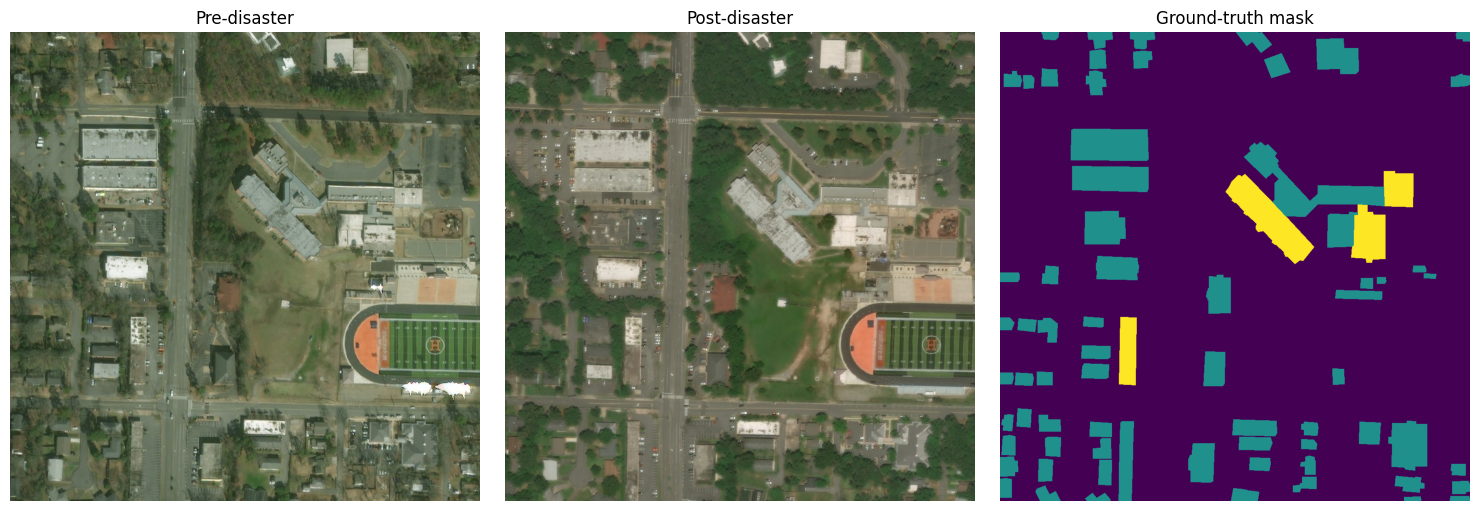

In [ ]:
from PIL import Image
import os
import matplotlib.pyplot as plt
import numpy as np

base = "/content/drive/MyDrive/Building_Damage_ResNet50/dataset/xbd_small/val"

pre_path = os.path.join(base, "images", "midwest-flooding_00000046_pre_disaster.jpg")
post_path = os.path.join(base, "images", "midwest-flooding_00000046_post_disaster.jpg")
mask_path = os.path.join(base, "masks", "midwest-flooding_00000046.png")

# Check files
for path in [pre_path, post_path, mask_path]:
    print(os.path.basename(path), "exists:", os.path.exists(path))

# Load images
pre = Image.open(pre_path).convert("RGB")
post = Image.open(post_path).convert("RGB")
mask = Image.open(mask_path)

print("\nPre image size:", pre.size)
print("Post image size:", post.size)
print("Mask size:", mask.size)
print("Mask values:", np.unique(np.array(mask)))

# Display
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(pre)
axes[0].set_title("Pre-disaster")
axes[1].imshow(post)
axes[1].set_title("Post-disaster")
axes[2].imshow(mask, cmap="viridis")
axes[2].set_title("Ground-truth mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import zipfile
from google.colab import files
import os

sample_folder = "/content/sample_damage_pair"
os.makedirs(sample_folder, exist_ok=True)

# Copy files with simpler names
Image.open(pre_path).save(os.path.join(sample_folder, "pre.png"))
Image.open(post_path).save(os.path.join(sample_folder, "post.png"))
Image.open(mask_path).save(os.path.join(sample_folder, "ground_truth.png"))

# Zip the three images
zip_path = "/content/midwest_flooding_sample.zip"

with zipfile.ZipFile(zip_path, "w") as zipf:
    for filename in ["pre.png", "post.png", "ground_truth.png"]:
        zipf.write(
            os.path.join(sample_folder, filename),
            arcname=filename
        )

# Download ZIP to your computer
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

base = "/content/drive/MyDrive"

for root, dirs, files in os.walk(base):
    if any(f.lower().endswith(('.png', '.jpg', '.jpeg')) for f in files):
        print("\nFolder:", root)
        print("Images:", [f for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg'))][:10])


Folder: /content/drive/MyDrive/Building_Damage_ResNet50/dataset/xbd_small/val/images
Images: ['midwest-flooding_00000046_post_disaster.jpg', 'midwest-flooding_00000046_pre_disaster.jpg', 'hurricane-florence_00000463_post_disaster.jpg', 'hurricane-florence_00000463_pre_disaster.jpg', 'midwest-flooding_00000434_pre_disaster.jpg', 'midwest-flooding_00000434_post_disaster.jpg', 'santa-rosa-wildfire_00000077_post_disaster.jpg', 'santa-rosa-wildfire_00000316_pre_disaster.jpg', 'socal-fire_00000413_pre_disaster.jpg', 'hurricane-michael_00000108_post_disaster.jpg']

Folder: /content/drive/MyDrive/Building_Damage_ResNet50/dataset/xbd_small/val/masks
Images: ['hurricane-florence_00000463.png', 'midwest-flooding_00000046.png', 'midwest-flooding_00000118.png', 'santa-rosa-wildfire_00000316.png', 'hurricane-matthew_00000036.png', 'socal-fire_00000413.png', 'hurricane-michael_00000108.png', 'santa-rosa-wildfire_00000077.png', 'midwest-flooding_00000434.png', 'midwest-flooding_00000373.png']

Folder

In [ ]:
import os

images_dir = "/content/drive/MyDrive/Building_Damage_ResNet50/dataset/xbd_small/val/images"
masks_dir = "/content/drive/MyDrive/Building_Damage_ResNet50/dataset/xbd_small/val/masks"

samples = {
    "Hurricane_Florence": "hurricane-florence_00000463",
    "Midwest_Flooding_2": "midwest-flooding_00000434",
    "Santa_Rosa_Wildfire": "santa-rosa-wildfire_00000077",
    "SoCal_Fire": "socal-fire_00000413",
}

for name, base in samples.items():
    pre = os.path.join(images_dir, base + "_pre_disaster.jpg")
    post = os.path.join(images_dir, base + "_post_disaster.jpg")
    mask = os.path.join(masks_dir, base + ".png")

    print(f"\n{name}")
    print("Pre image:", os.path.exists(pre))
    print("Post image:", os.path.exists(post))
    print("Mask:", os.path.exists(mask))


Hurricane_Florence
Pre image: True
Post image: True
Mask: True

Midwest_Flooding_2
Pre image: True
Post image: True
Mask: True

Santa_Rosa_Wildfire
Pre image: True
Post image: True
Mask: True

SoCal_Fire
Pre image: True
Post image: True
Mask: True


In [ ]:
import os
import shutil
import zipfile
from google.colab import files

images_dir = "/content/drive/MyDrive/Building_Damage_ResNet50/dataset/xbd_small/val/images"
masks_dir = "/content/drive/MyDrive/Building_Damage_ResNet50/dataset/xbd_small/val/masks"

samples = {
    "Hurricane_Florence": "hurricane-florence_00000463",
    "Midwest_Flooding_2": "midwest-flooding_00000434",
    "Santa_Rosa_Wildfire": "santa-rosa-wildfire_00000077",
    "SoCal_Fire": "socal-fire_00000413",
}

export_dir = "/content/four_additional_samples"
zip_path = "/content/four_additional_samples.zip"

# Start fresh
if os.path.exists(export_dir):
    shutil.rmtree(export_dir)

os.makedirs(export_dir)

# Organize each sample
for folder_name, base in samples.items():
    sample_folder = os.path.join(export_dir, folder_name)
    os.makedirs(sample_folder)

    shutil.copy(
        os.path.join(images_dir, base + "_pre_disaster.jpg"),
        os.path.join(sample_folder, "pre.jpg")
    )

    shutil.copy(
        os.path.join(images_dir, base + "_post_disaster.jpg"),
        os.path.join(sample_folder, "post.jpg")
    )

    shutil.copy(
        os.path.join(masks_dir, base + ".png"),
        os.path.join(sample_folder, "ground_truth.png")
    )

# Create ZIP
if os.path.exists(zip_path):
    os.remove(zip_path)

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, filenames in os.walk(export_dir):
        for filename in filenames:
            filepath = os.path.join(root, filename)
            arcname = os.path.relpath(filepath, export_dir)
            zipf.write(filepath, arcname)

print("ZIP created successfully!")
print("Samples:", len(samples))
print("ZIP size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

# Download to your computer
files.download(zip_path)

ZIP created successfully!
Samples: 4
ZIP size: 1.82 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>